In [3]:
import gymnasium as gym
from gymnasium import spaces
from concurrent.futures import ThreadPoolExecutor
from dataclasses import asdict, dataclass, replace
from itertools import product
from pathlib import Path
from threading import Lock
from time import perf_counter
import hashlib
import numpy as np
import matplotlib.pyplot as plt
from copy import deepcopy
import torch
from torch import nn
from torch.distributions import Categorical

### Objetivo

Implementar un agente de RL que aprenda a invertir en un entorno simulado con un único activo.

### Definición del entorno

El **estado** (observación) es una tupla de la forma ``(tendencia, posición)`` en la que:

- ``tendencia`` es la tendencia del precio, calculada a partir de las últimas 6 observaciones.

- ``posición`` es $1$ si el agente posee el activo y $0$ si no lo posee.

En cada momento, las **acciones** son:

- $0$ = vender

- $1$ = mantener

- $2$ = comprar

Obviamente, la acción *vender* sólo tendrá efecto si el agente es poseedor del activo, y la acción *comprar* sólo tendrá efecto cuando el agente no posee el activo.


In [4]:
class SimpleTradingEnv(gym.Env):
    metadata = {"render_modes": ["human"]}

    def __init__(self, prices):
        super(SimpleTradingEnv, self).__init__()
        self.prices = prices
        self.max_steps = len(prices) - 1

        # Acciones: 0 = Vender, 1 = Mantener, 2 = Comprar
        self.action_space = spaces.Discrete(3)

        # Estado: [tendencia_precio (-1 a 1), posicion_actual (0 o 1)]
        self.observation_space = spaces.Box(
            low=np.array([-1.0, 0], dtype=np.float32),
            high=np.array([1.0, 1], dtype=np.float32),
            dtype=np.float32
        )

    def reset(self, seed=None):
        super().reset(seed=seed)
        self.current_step = 5  # Empezar con suficiente historia para la media
        self.position = 0      # 0: sin activo, 1: con activo

        # Gestión del capital
        self.initial_balance = 1000.0
        self.balance = self.initial_balance  # Valor total del portafolio (Efectivo + Activos)
        self.cash = self.initial_balance     # Dinero en efectivo disponible
        self.shares = 0.0                    # Cantidad de acciones poseídas

        return self._get_obs(), {}

    def _get_obs(self):
        # Calcular tendencia simple basada en los últimos 5 pasos
        window = self.prices[self.current_step - 5 : self.current_step + 1]
        trend = (window[-1] - np.mean(window)) / np.mean(window)
        return np.array([np.clip(trend, -1.0, 1.0), self.position], dtype=np.float32)

    def step(self, action):
        prev_price = self.prices[self.current_step]
        self.current_step += 1
        curr_price = self.prices[self.current_step]

        reward = 0.0
        cost_rate = 0.001  # Comisión del 0.1% por transacción

        # 1. Ejecutar acciones y actualizar efectivo/acciones
        if action == 2 and self.position == 0:  # Comprar
            # Usar todo el efectivo disponible para comprar acciones al precio anterior
            commission = self.cash * cost_rate
            effective_cash = self.cash - commission
            self.shares = effective_cash / prev_price
            self.cash = 0.0
            self.position = 1
            reward -= cost_rate

        elif action == 0 and self.position == 1:  # Vender
            # Vender todas las acciones al precio anterior
            sale_value = self.shares * prev_price
            commission = sale_value * cost_rate
            self.cash = sale_value - commission
            self.shares = 0.0
            self.position = 0
            reward -= cost_rate

        # 2. Calcular recompensa por variación del precio si mantiene la posición
        if self.position == 1:
            price_change = (curr_price - prev_price) / prev_price
            reward += price_change

        # 3. Actualizar el balance total (Net Worth) al finalizar el paso
        if self.position == 1:
            self.balance = self.cash + (self.shares * curr_price)
        else:
            self.balance = self.cash

        terminated = self.current_step >= self.max_steps
        truncated = False

        # Opcional: puedes pasar el balance actual en el diccionario de info
        info = {"balance": self.balance}

        return self._get_obs(), reward, terminated, truncated, info

### Funciones para generar precios

Se proponen cuatro funciones generadoras de precios. Las pruebas deben hacerse al menos con estas cuatro funciones. Si se desea, pueden añadirse otras funciones de diferentes características, o incluso probar con alguna serie de precios real.

#### 1. Tendencia suave + componente cíclica

In [5]:
def _resolver_rng(rng):
    """Devuelve un RNG local; nunca depende del estado global de NumPy."""
    if rng is None:
        return np.random.default_rng()
    if not isinstance(rng, np.random.Generator):
        raise TypeError("rng debe ser una instancia de np.random.Generator")
    return rng


def generar_precios(n_steps=1000, rng=None):
    rng = _resolver_rng(rng)
    # Combinar una tendencia suave (drift) + componente cíclico + ruido
    t = np.linspace(0, 50, n_steps)
    drift = 0.0005 * t
    ciclo = np.sin(t) * 0.05
    ruido = rng.normal(0, 0.1, n_steps)

    # Precio base acumulado
    retornos = drift + ciclo + ruido
    precios = 100 * np.cumprod(1 + retornos)
    return precios

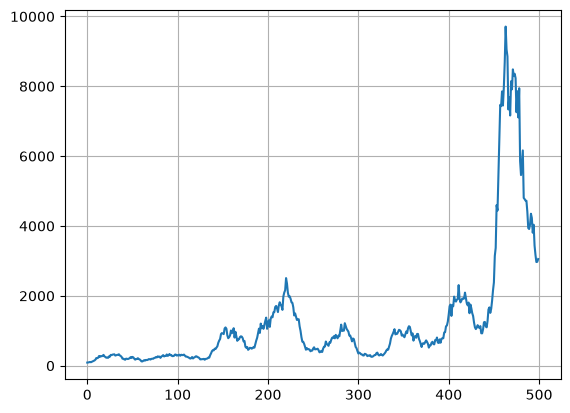

In [6]:
precios = generar_precios(n_steps=500, rng=np.random.default_rng(100))

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

#### 2. Movimiento browniano

In [7]:
def generar_precios_browniano(
    n_steps=1000,
    start_price=100.0,
    mu=0.0001,
    sigma=0.02,
    rng=None,
):
    """
    Genera precios usando Movimiento Browniano Geométrico.
    - mu: Tendencia o deriva esperada (drift).
    - sigma: Volatilidad (desviación estándar de los retornos).
    """
    rng = _resolver_rng(rng)
    dt = 1.0
    # Retornos logarítmicos distribuidos normalmente
    retornos = rng.normal(
        (mu - 0.5 * sigma**2) * dt,
        sigma * np.sqrt(dt),
        n_steps,
    )
    precios = start_price * np.cumprod(np.exp(retornos))
    return precios

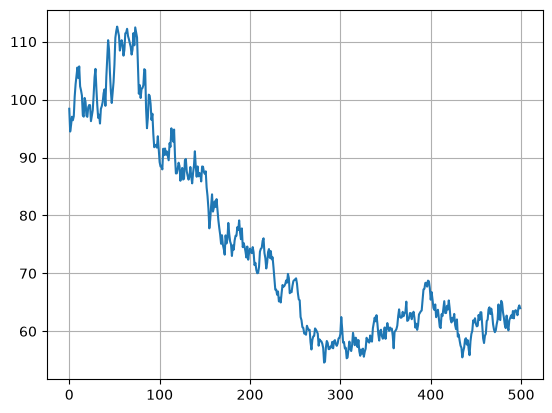

In [8]:
precios = generar_precios_browniano(
    n_steps=500, rng=np.random.default_rng(101)
)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

#### 3. Reversión a la media

In [9]:
def generar_precios_reversion_media(
    n_steps=1000,
    start_price=100.0,
    mean_price=100.0,
    kappa=0.05,
    volatility=0.02,
    rng=None,
):
    """
    Genera precios que tienden a revertir hacia un valor medio.
    - mean_price: El precio objetivo o de equilibrio.
    - kappa: Velocidad de reversión (cuánto más alto, más rápido vuelve al valor medio).
    - volatility: Magnitud del ruido aleatorio añadido en cada paso.
    """
    rng = _resolver_rng(rng)
    precios = np.zeros(n_steps)
    precios[0] = start_price

    for t in range(1, n_steps):
        # Fuerza de atracción hacia la media + ruido aleatorio
        delta = (
            kappa * (mean_price - precios[t-1])
            + rng.normal(0, volatility * mean_price)
        )
        precios[t] = precios[t-1] + delta

        # Evitar precios negativos o cero por seguridad
        precios[t] = max(precios[t], 0.1)

    return precios

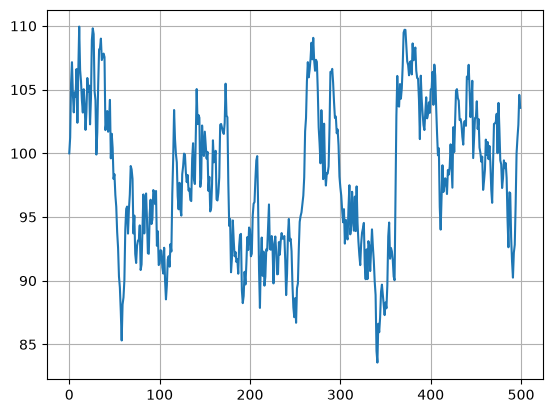

In [10]:
precios = generar_precios_reversion_media(
    n_steps=500, rng=np.random.default_rng(102)
)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

#### 4. Alternancia entre regímenes alcistas y bajistas

In [11]:
def generar_precios_regimenes(
    n_steps=1000, start_price=100.0, rng=None
):
    """
    Genera precios alternando entre regímenes alcistas y bajistas de forma estocástica.
    """
    rng = _resolver_rng(rng)
    precios = np.zeros(n_steps)
    precios[0] = start_price

    # Estado inicial: 0 = Alcista, 1 = Bajista
    estado = 0

    retornos = []
    for _ in range(n_steps):
        # Probabilidad de cambiar de régimen en cada paso
        if rng.random() < 0.02:
            estado = 1 - estado

        if estado == 0:  # Régimen alcista
            ret = rng.normal(0.001, 0.01)
        else:            # Régimen bajista (caídas con más ruido)
            ret = rng.normal(-0.0015, 0.025)

        retornos.append(ret)

    retornos = np.array(retornos)
    precios = start_price * np.cumprod(1 + retornos)

    # Asegurar que no haya valores negativos
    precios = np.maximum(precios, 0.1)
    return precios

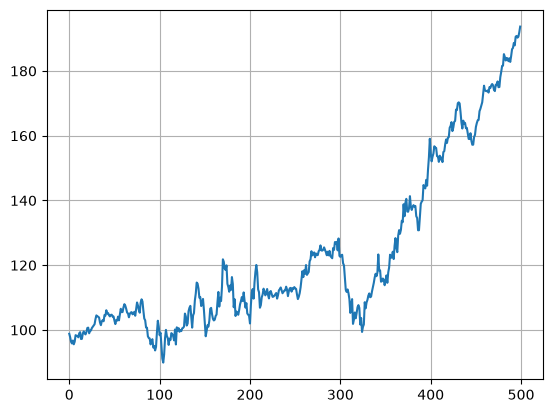

In [12]:
precios = generar_precios_regimenes(
    n_steps=500, rng=np.random.default_rng(103)
)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

### Protocolo común de reproducibilidad

Para que los resultados de distintos notebooks sean comparables, todos deben reutilizar **los mismos bancos de series**, sin regenerarlos a partir del estado global de NumPy. Se fija el siguiente protocolo:

| Partición | Series por generador | Precios por serie | Semilla de precios | Semilla de acciones | Uso |
|:--|--:|--:|--:|--:|:--|
| Validación | 50 | 500 | 5.000 | 6.000 | Selección de hiperparámetros |
| Test final | 200 | 500 | 10.000 | 20.000 | Una única evaluación final |

Las semillas de entrenamiento comunes son `(101, 202, 303, 404, 505)`. Cada combinación `(partición, generador, número de serie)` crea un `Generator` independiente mediante `SeedSequence`; por ello, ejecutar otras celdas o cambiar su orden no altera ninguna serie de evaluación. Las huellas SHA-256 permiten verificar que todos los compañeros han generado exactamente los mismos datos.

> El conjunto de test no debe utilizarse para elegir hiperparámetros, número de episodios ni arquitectura. Las políticas deterministas deben evaluarse sin muestreo; para políticas o baselines estocásticos se debe usar `protocol.action_rng(...)`.

> En A3C, fijar semillas no garantiza que dos entrenamientos sean idénticos bit a bit: el orden de las actualizaciones asíncronas también depende de la planificación de los *workers*. La comparación debe hacerse sobre estos mismos bancos y agregando las cinco semillas de entrenamiento, no sobre una sola ejecución.

In [13]:
@dataclass(frozen=True)
class EvaluationProtocol:
    """Define un banco de evaluación reproducible e independiente."""

    name: str
    n_series: int
    n_steps: int
    price_seed: int
    action_seed: int

    def __post_init__(self):
        if not self.name:
            raise ValueError("name no puede estar vacío")
        if self.n_series <= 0:
            raise ValueError("n_series debe ser positivo")
        if self.n_steps < 7:
            raise ValueError("n_steps debe ser al menos 7")
        if self.price_seed < 0 or self.action_seed < 0:
            raise ValueError("las semillas no pueden ser negativas")

    @staticmethod
    def _rng(base_seed, generator_id, series_index):
        if generator_id < 0 or series_index < 0:
            raise ValueError("generator_id y series_index no pueden ser negativos")
        seed_sequence = np.random.SeedSequence(
            [base_seed, generator_id, series_index]
        )
        return np.random.default_rng(seed_sequence)

    def price_rng(self, generator_id, series_index):
        return self._rng(self.price_seed, generator_id, series_index)

    def action_rng(self, generator_id, series_index):
        return self._rng(self.action_seed, generator_id, series_index)

    def generate_dataset(self, price_generator, generator_id):
        series = [
            np.asarray(
                price_generator(
                    n_steps=self.n_steps,
                    rng=self.price_rng(generator_id, series_index),
                ),
                dtype=np.float64,
            )
            for series_index in range(self.n_series)
        ]
        dataset = np.stack(series)
        if dataset.shape != (self.n_series, self.n_steps):
            raise ValueError("el generador devolvió una forma no válida")
        if not np.all(np.isfinite(dataset)) or np.any(dataset <= 0.0):
            raise ValueError("los precios deben ser finitos y positivos")
        return dataset


TRAINING_SEEDS = (101, 202, 303, 404, 505)
VALIDATION_PROTOCOL = EvaluationProtocol(
    name="validation",
    n_series=50,
    n_steps=500,
    price_seed=5_000,
    action_seed=6_000,
)
TEST_PROTOCOL = EvaluationProtocol(
    name="test",
    n_series=200,
    n_steps=500,
    price_seed=10_000,
    action_seed=20_000,
)

# Los identificadores son explícitos: no dependen del orden de un diccionario.
PRICE_GENERATORS = {
    "tendencia_ciclo": (0, generar_precios),
    "browniano": (1, generar_precios_browniano),
    "reversion_media": (2, generar_precios_reversion_media),
    "regimenes": (3, generar_precios_regimenes),
}


def generate_evaluation_datasets(protocol):
    """Genera todos los mercados definidos bajo un mismo protocolo."""
    return {
        name: protocol.generate_dataset(generator, generator_id)
        for name, (generator_id, generator) in PRICE_GENERATORS.items()
    }


def dataset_fingerprint(dataset):
    """Huella portable de una matriz de precios normalizada a float64."""
    normalized = np.ascontiguousarray(dataset, dtype="<f8")
    return hashlib.sha256(normalized.tobytes()).hexdigest()


VALIDATION_DATASETS = generate_evaluation_datasets(VALIDATION_PROTOCOL)
TEST_DATASETS = generate_evaluation_datasets(TEST_PROTOCOL)

for protocol, datasets in (
    (VALIDATION_PROTOCOL, VALIDATION_DATASETS),
    (TEST_PROTOCOL, TEST_DATASETS),
):
    print(
        f"{protocol.name}: {protocol.n_series} series x "
        f"{protocol.n_steps} precios"
    )
    for name, dataset in datasets.items():
        print(f"  {name}: {dataset_fingerprint(dataset)}")

validation: 50 series x 500 precios
  tendencia_ciclo: 1894c23f442a7ab97214d0a8a7923e6113ea6eea0b37781173033dfe2f3cf514
  browniano: 14916f368f63b8df8cdcc39af5a1d518f95ea9d30f30ae47fd924c98cd0ed233
  reversion_media: 68065aea4fddafc71cd299179d5ada62ff354bbc934f642bb79c675549af8e98
  regimenes: 4cafb200dec1822a113250f9626bb12c94b3cdf309bc001841c3f933d00dc658
test: 200 series x 500 precios
  tendencia_ciclo: f7ba229a24755ad123d0b01e608ed72e16f347bb16be7c87fd309e1afb38763d
  browniano: d05b4102b634985e678b6a0511fcd0497d524f3b4b72d396043ebe25e362688d
  reversion_media: 16ac74754351e609c738490d97f7c69383a10a31c4920d4b25423df215d86339
  regimenes: 061f1f1ef1f21f034eea600b65d5d87702d4430699cf38250fb552fb58b013ce


### Agente aleatorio

Como línea base, se proporciona un agente aleatorio que en cada instante selecciona la acción al azar. A continuación se compara su rendimiento en un episodio con la estrategia *buy & hold*.

In [14]:
n_steps = 500
demo_seed = 30_000
prices = generar_precios(
    n_steps, rng=np.random.default_rng(demo_seed)
)
env = SimpleTradingEnv(prices)

obs, info = env.reset(seed=demo_seed)
env.action_space.seed(demo_seed)
terminated = False
step_count = 0

balances = [env.balance]
actions_taken = []
positions = []

while not terminated:
    action = env.action_space.sample()
    positions.append(env.position)
    actions_taken.append(action)

    obs, reward, terminated, truncated, info = env.step(action)
    balances.append(env.balance)

positions = np.array(positions)
actions_taken = np.array(actions_taken)
valid_prices = prices[5:-1]

In [15]:
prices_on = valid_prices.copy()
prices_on[positions==0] = np.nan
prices_off = valid_prices.copy()
prices_off[positions==1] = np.nan

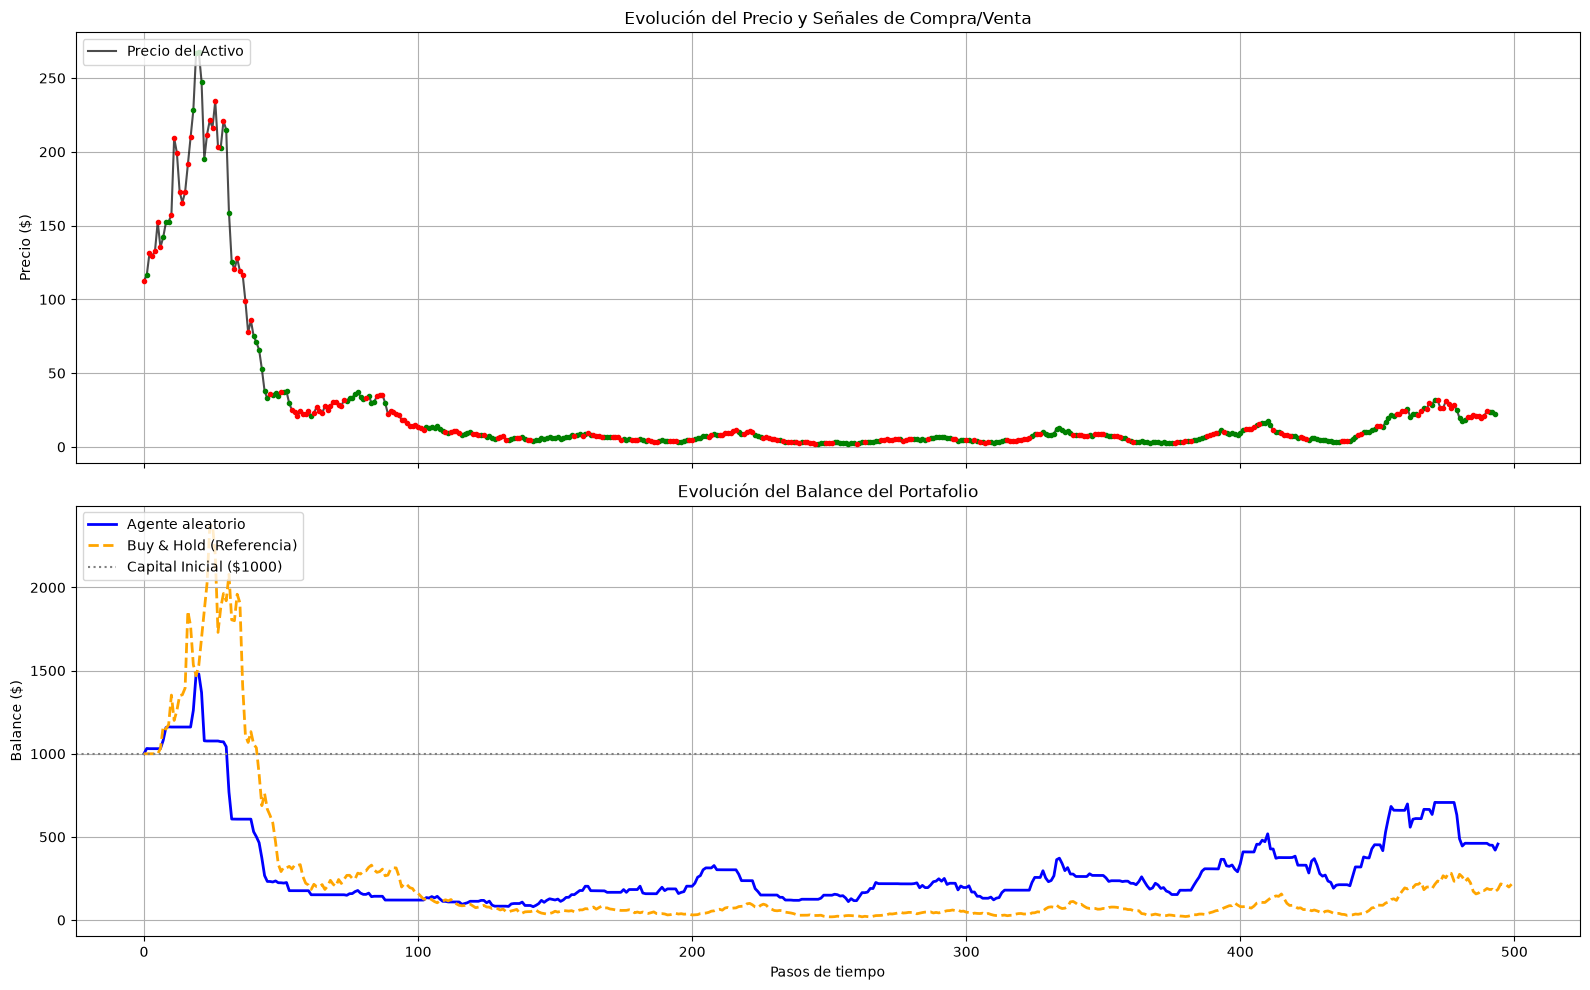

In [16]:
# --- Estrategia Buy & Hold para el panel de balance ---
bh_initial_cash = 1000.0
bh_start_price = prices[5]
bh_shares = (bh_initial_cash * 0.999) / bh_start_price
bh_balances = [bh_initial_cash if i < 5 else bh_shares * p for i, p in enumerate(prices)]

# --- Crear la figura con 2 Subgráficas ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

# PANEL 1: Evolución del precio y señales de Trading
ax1.plot(valid_prices, label="Precio del Activo", color="black", alpha=0.7, linewidth=1.5)
ax1.plot(prices_on, 'g.')
ax1.plot(prices_off, 'r.')
ax1.set_title("Evolución del Precio y Señales de Compra/Venta")
ax1.set_ylabel("Precio ($)")
ax1.legend(loc="upper left")
ax1.grid(True)

# PANEL 2: Evolución del Balance (Portafolio)
ax2.plot(balances, label="Agente aleatorio", color="blue", linewidth=2)
ax2.plot(bh_balances, label="Buy & Hold (Referencia)", color="orange", linestyle="--", linewidth=2)
ax2.axhline(y=1000, color="gray", linestyle=":", label="Capital Inicial ($1000)")

ax2.set_title("Evolución del Balance del Portafolio")
ax2.set_xlabel("Pasos de tiempo")
ax2.set_ylabel("Balance ($)")
ax2.legend(loc="upper left")
ax2.grid(True)

plt.tight_layout()
plt.show()

### Ejercicios y notas sobre la implementación

1. Implementar los algoritmos vistos en clase y probarlos con distintas funciones de generación de los precios. Deben implementarse al menos los algoritmos *DQN* y *A3C*, usando al menos las cuatro funciones de generación de precio propuestas.

   - Cada agente debe entrenarse con varios (muchos) episodios, y cada episodio debería usar una serie de precios distinta, aunque todas deberían ser generadas por la misma función. De este modo el agente puede aprender las regularidades de cada tipo de *mercado* sin repetir siempre los mismos datos para entrenar.

   - Para evaluar los agentes entrenados, se deberían usar datos de *test*, series de precios nuevas generadas a partir de la misma función usada durante el entrenamiento. Los resultados deberían promediarse sobre varias series de test.

2. Analizar las soluciones obtenidas para cada función de generación de precios, y compararlas con el agente aleatorio y con la estrategia *buy & hold*. Razonar si la estrategia encontrada en cada caso es la esperada.

3. Ajustar de manera adecuada los hiperparámetros de cada modelo, en particular el factor de aprendizaje $\alpha$, la tasa de exploración $\epsilon$ (probablemente con decaimiento temporal), el factor de descuento $\gamma$, y el número de episodios de entrenamiento.

4. Comparar en una tabla las soluciones obtenidas con cada algoritmo, incluyendo los *baselines*, sobre cada problema (función generadora de precios). Analizar al menos el rendimiento y el tiempo de convergencia.



### Entrega

Debe entregarse un documento en pdf de un **máximo de dos páginas** con un resumen de las pruebas realizadas, los resultados obtenidos y las conclusiones extraidas.

Las entregas se harán por grupos. Cada grupo de TFM realizará una entrega.

La fecha tope para la entrega es el **5/11/2026**, a las **23:59**.

**Importante:** Una primera versión del documento se deberá entregar por e-mail a manuel.smontanes@gmail.com antes de la clase del jueves 5 de noviembre. En dicha clase cada grupo presentará su trabajo y lo discutirá con el profesor durante un máximo de 15 minutos. Los comentarios recibidos pueden usarse para mejorar el documento para la entrega final.

De cara a organizar las presentaciones, un representante de cada grupo debe enviar un e-mail al profesor antes del martes 3 de noviembre. Ese mismo día os indicaré, mediante mensaje a los representantes, el orden de presentación.

### Evaluación

La realización de los ejercicios y pruebas propuestos garantiza el aprobado en la práctica (50%). El otro 50% se obtendrá valorando la realización de pruebas que vayan más allá de los mínimos planteados (10%), la calidad de presentación de los resultados (20%), la justificación de las decisiones de diseño tomadas (10%) y el análisis crítico de las soluciones obtenidas (10%).

### Arquitectura neuronal para A3C

El actor y el crítico comparten un extractor de características. El actor produce los *logits* de las acciones y el crítico estima el valor del estado.

```text
Estado: [tendencia, posición]
             (2)
              │
        Linear(2, 32)
              │
             Tanh
              │
       Linear(32, 32)
              │
             Tanh
              │
      Características compartidas
              (32)
        ┌───────┴───────┐
        │               │
  Cabeza actor     Cabeza crítico
  Linear(32, 3)    Linear(32, 1)
        │               │
  logits de las       V(estado)
  tres acciones        escalar
```

Los *logits* se pasan directamente a una distribución categórica, sin aplicar `softmax` manualmente.

In [17]:
class ActorCriticNetwork(nn.Module):
    """Red neuronal compartida para una política y una función de valor."""

    def __init__(self, observation_dim, action_dim, hidden_dim=32):
        super().__init__()
        if observation_dim <= 0:
            raise ValueError("observation_dim debe ser positivo")
        if action_dim <= 0:
            raise ValueError("action_dim debe ser positivo")
        if hidden_dim <= 0:
            raise ValueError("hidden_dim debe ser positivo")

        self.observation_dim = observation_dim
        self.action_dim = action_dim
        self.feature_extractor = nn.Sequential(
            nn.Linear(observation_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
        )
        self.actor_head = nn.Linear(hidden_dim, action_dim)
        self.critic_head = nn.Linear(hidden_dim, 1)

        self._initialize_parameters()

    def _initialize_parameters(self):
        """Inicializa las capas para estabilizar el comienzo del entrenamiento."""
        hidden_gain = nn.init.calculate_gain("tanh")
        for layer in self.feature_extractor:
            if isinstance(layer, nn.Linear):
                nn.init.orthogonal_(layer.weight, gain=hidden_gain)
                nn.init.zeros_(layer.bias)

        # Una ganancia pequeña produce una política inicial casi uniforme.
        nn.init.orthogonal_(self.actor_head.weight, gain=0.01)
        nn.init.zeros_(self.actor_head.bias)
        nn.init.orthogonal_(self.critic_head.weight, gain=1.0)
        nn.init.zeros_(self.critic_head.bias)

    def forward(self, observations):
        """Devuelve los logits de las acciones y V(s)."""
        if observations.shape[-1] != self.observation_dim:
            raise ValueError(
                f"La última dimensión debe ser {self.observation_dim}, "
                f"pero se recibió {observations.shape[-1]}"
            )

        features = self.feature_extractor(observations)
        action_logits = self.actor_head(features)
        state_values = self.critic_head(features).squeeze(-1)
        return action_logits, state_values

    def get_action_distribution(self, observations):
        """Construye la distribución categórica sin aplicar softmax manual."""
        action_logits, _ = self(observations)
        return Categorical(logits=action_logits)

    def act(self, observations, deterministic=False):
        """Selecciona acciones y devuelve la información necesaria para A3C."""
        action_logits, state_values = self(observations)
        distribution = Categorical(logits=action_logits)
        if deterministic:
            actions = action_logits.argmax(dim=-1)
        else:
            actions = distribution.sample()

        return (
            actions,
            distribution.log_prob(actions),
            distribution.entropy(),
            state_values,
        )

### Retornos, ventajas y pérdidas de A3C

Cada *worker* recopilará un fragmento de trayectoria de hasta $n$ pasos. El retorno se calcula hacia atrás:

$$R_t = r_t + \gamma R_{t+1}$$

Al terminar un episodio, el valor de arranque es $R_T=0$. Si el fragmento acaba porque se alcanzó su longitud máxima pero el episodio continúa, se utiliza $R_T=V(s_T)$ (*bootstrap*).

La ventaja indica si la acción produjo un resultado mejor o peor que el esperado por el crítico:

$$A_t = R_t - V(s_t)$$

A partir de ella se calculan tres componentes:

- Actor: $L_\pi=-\mathbb{E}[\log \pi(a_t|s_t)\,\operatorname{stopgrad}(A_t)]$.
- Crítico: $L_V=\mathbb{E}[(R_t-V(s_t))^2]$.
- Entropía: $H(\pi)$, que favorece la exploración.

La pérdida conjunta es $L=L_\pi+c_VL_V-c_EH(\pi)$. La ventaja se desconecta del grafo solo en la pérdida del actor para impedir que este actualice indirectamente la cabeza del crítico.

In [18]:
def compute_n_step_returns(rewards, bootstrap_value, gamma):
    """Calcula los retornos descontados de un fragmento de trayectoria."""
    if not 0.0 <= gamma <= 1.0:
        raise ValueError("gamma debe pertenecer a [0, 1]")
    if len(rewards) == 0:
        raise ValueError("rewards no puede estar vacío")
    if not isinstance(bootstrap_value, torch.Tensor):
        raise TypeError("bootstrap_value debe ser un tensor de PyTorch")
    if bootstrap_value.numel() != 1:
        raise ValueError("bootstrap_value debe contener un único valor")

    running_return = bootstrap_value.detach().reshape(())
    discounted_returns = []

    with torch.no_grad():
        for reward in reversed(rewards):
            reward_tensor = torch.as_tensor(
                reward,
                dtype=running_return.dtype,
                device=running_return.device,
            )
            if reward_tensor.numel() != 1:
                raise ValueError("cada recompensa debe ser escalar")

            running_return = (
                reward_tensor.reshape(()) + gamma * running_return
            )
            discounted_returns.append(running_return)

    discounted_returns.reverse()
    return torch.stack(discounted_returns)


def compute_advantages(returns, state_values):
    """Calcula A_t = R_t - V(s_t), conservando el gradiente del crítico."""
    if returns.ndim != 1 or state_values.ndim != 1:
        raise ValueError("returns y state_values deben ser vectores")
    if returns.shape != state_values.shape:
        raise ValueError("returns y state_values deben tener la misma forma")

    return returns.detach() - state_values


def compute_a3c_losses(
    log_probabilities,
    entropies,
    state_values,
    returns,
    value_loss_coefficient=0.5,
    entropy_coefficient=0.01,
):
    """Combina las pérdidas del actor, del crítico y la entropía."""
    if value_loss_coefficient < 0.0:
        raise ValueError("value_loss_coefficient no puede ser negativo")
    if entropy_coefficient < 0.0:
        raise ValueError("entropy_coefficient no puede ser negativo")

    advantages = compute_advantages(returns, state_values)
    expected_shape = advantages.shape
    if log_probabilities.shape != expected_shape:
        raise ValueError(
            "log_probabilities debe tener la misma forma que returns"
        )
    if entropies.shape != expected_shape:
        raise ValueError("entropies debe tener la misma forma que returns")

    actor_loss = -(log_probabilities * advantages.detach()).mean()
    critic_loss = advantages.square().mean()
    entropy_bonus = entropies.mean()
    total_loss = (
        actor_loss
        + value_loss_coefficient * critic_loss
        - entropy_coefficient * entropy_bonus
    )

    return {
        "total_loss": total_loss,
        "actor_loss": actor_loss,
        "critic_loss": critic_loss,
        "entropy_bonus": entropy_bonus,
        "advantages": advantages.detach(),
    }

### Worker de A3C

Cada *worker* mantiene una copia local de la red. Durante un episodio repite el siguiente ciclo:

1. Sincroniza la red local con el modelo global.
2. Recopila un *rollout* de hasta `rollout_steps`.
3. Calcula los retornos, las ventajas y la pérdida A3C.
4. Retropropaga sobre la red local y limita la norma de sus gradientes.
5. Copia esos gradientes al modelo global y ejecuta un paso del optimizador.

El bloqueo solo protege la actualización del modelo global. La interacción de cada worker con su entorno y el cálculo de gradientes quedan fuera del bloqueo, por lo que podrán ejecutarse de forma concurrente. En esta fase se define y prueba la lógica del worker; la coordinación asíncrona se añadirá después.

In [19]:
class A3CWorker:
    """Recopila experiencia y aplica actualizaciones al modelo global."""

    def __init__(
        self,
        worker_id,
        global_model,
        optimizer,
        update_lock,
        rollout_steps=20,
        gamma=0.99,
        value_loss_coefficient=0.5,
        entropy_coefficient=0.01,
        max_gradient_norm=40.0,
    ):
        if worker_id < 0:
            raise ValueError("worker_id no puede ser negativo")
        if rollout_steps <= 0:
            raise ValueError("rollout_steps debe ser positivo")
        if not 0.0 <= gamma <= 1.0:
            raise ValueError("gamma debe pertenecer a [0, 1]")
        if value_loss_coefficient < 0.0:
            raise ValueError(
                "value_loss_coefficient no puede ser negativo"
            )
        if entropy_coefficient < 0.0:
            raise ValueError("entropy_coefficient no puede ser negativo")
        if max_gradient_norm <= 0.0:
            raise ValueError("max_gradient_norm debe ser positivo")
        if any(
            parameter.device.type != "cpu"
            for parameter in global_model.parameters()
        ):
            raise ValueError("A3CWorker requiere un modelo global en CPU")

        self.worker_id = worker_id
        self.global_model = global_model
        self.local_model = deepcopy(global_model)
        self.optimizer = optimizer
        self.update_lock = update_lock
        self.rollout_steps = rollout_steps
        self.gamma = gamma
        self.value_loss_coefficient = value_loss_coefficient
        self.entropy_coefficient = entropy_coefficient
        self.max_gradient_norm = max_gradient_norm

    def _copy_global_parameters_to_local(self):
        self.local_model.load_state_dict(self.global_model.state_dict())

    def synchronize(self):
        """Obtiene una instantánea coherente de los parámetros globales."""
        with self.update_lock:
            self._copy_global_parameters_to_local()

    @staticmethod
    def _observation_to_tensor(observation):
        return torch.as_tensor(observation, dtype=torch.float32)

    def collect_rollout(self, env, observation):
        """Recopila como máximo rollout_steps transiciones consecutivas."""
        rewards = []
        log_probabilities = []
        entropies = []
        state_values = []
        terminated = False
        truncated = False
        info = {}

        for _ in range(self.rollout_steps):
            observation_tensor = self._observation_to_tensor(observation)
            action, log_probability, entropy, state_value = (
                self.local_model.act(observation_tensor)
            )
            next_observation, reward, terminated, truncated, info = env.step(
                int(action.item())
            )

            rewards.append(float(reward))
            log_probabilities.append(log_probability)
            entropies.append(entropy)
            state_values.append(state_value)
            observation = next_observation

            if terminated or truncated:
                break

        if terminated or truncated:
            bootstrap_value = torch.zeros_like(state_values[-1])
        else:
            with torch.no_grad():
                _, bootstrap_value = self.local_model(
                    self._observation_to_tensor(observation)
                )

        returns = compute_n_step_returns(
            rewards=rewards,
            bootstrap_value=bootstrap_value,
            gamma=self.gamma,
        )
        losses = compute_a3c_losses(
            log_probabilities=torch.stack(log_probabilities),
            entropies=torch.stack(entropies),
            state_values=torch.stack(state_values),
            returns=returns,
            value_loss_coefficient=self.value_loss_coefficient,
            entropy_coefficient=self.entropy_coefficient,
        )

        return {
            "observation": observation,
            "terminated": terminated,
            "truncated": truncated,
            "info": info,
            "steps": len(rewards),
            "reward": float(sum(rewards)),
            "losses": losses,
        }

    def apply_gradients(self, total_loss):
        """Calcula gradientes locales y actualiza el modelo global."""
        self.local_model.zero_grad(set_to_none=True)
        total_loss.backward()
        gradient_norm = nn.utils.clip_grad_norm_(
            self.local_model.parameters(),
            self.max_gradient_norm,
        )

        with self.update_lock:
            self.optimizer.zero_grad(set_to_none=True)
            for global_parameter, local_parameter in zip(
                self.global_model.parameters(),
                self.local_model.parameters(),
            ):
                if local_parameter.grad is None:
                    global_parameter.grad = None
                else:
                    global_parameter.grad = (
                        local_parameter.grad.detach().clone()
                    )

            self.optimizer.step()
            self._copy_global_parameters_to_local()

        return float(gradient_norm)

    def train_episode(self, prices, seed=None):
        """Entrena sobre una serie de precios y devuelve sus métricas."""
        prices = np.asarray(prices, dtype=np.float64)
        if prices.ndim != 1 or len(prices) < 7:
            raise ValueError("prices debe ser un vector con al menos 7 valores")
        if not np.all(np.isfinite(prices)) or np.any(prices <= 0.0):
            raise ValueError("todos los precios deben ser finitos y positivos")

        env = SimpleTradingEnv(prices)
        observation, _ = env.reset(seed=seed)
        if seed is not None:
            env.action_space.seed(seed)

        self.synchronize()
        terminated = False
        truncated = False
        total_reward = 0.0
        total_steps = 0
        rollout_metrics = []
        info = {"balance": env.balance}

        while not (terminated or truncated):
            rollout = self.collect_rollout(env, observation)
            losses = rollout["losses"]
            gradient_norm = self.apply_gradients(losses["total_loss"])

            observation = rollout["observation"]
            terminated = rollout["terminated"]
            truncated = rollout["truncated"]
            info = rollout["info"]
            total_reward += rollout["reward"]
            total_steps += rollout["steps"]
            rollout_metrics.append(
                {
                    "actor_loss": float(losses["actor_loss"].detach()),
                    "critic_loss": float(losses["critic_loss"].detach()),
                    "entropy": float(losses["entropy_bonus"].detach()),
                    "gradient_norm": gradient_norm,
                }
            )

        return {
            "worker_id": self.worker_id,
            "episode_reward": total_reward,
            "final_balance": float(info["balance"]),
            "episode_return": float(
                info["balance"] / env.initial_balance - 1.0
            ),
            "steps": total_steps,
            "rollouts": len(rollout_metrics),
            "mean_actor_loss": float(np.mean(
                [metric["actor_loss"] for metric in rollout_metrics]
            )),
            "mean_critic_loss": float(np.mean(
                [metric["critic_loss"] for metric in rollout_metrics]
            )),
            "mean_entropy": float(np.mean(
                [metric["entropy"] for metric in rollout_metrics]
            )),
            "mean_gradient_norm": float(np.mean(
                [metric["gradient_norm"] for metric in rollout_metrics]
            )),
        }

### Coordinador del entrenamiento A3C

El coordinador crea el modelo y el optimizador globales, construye los workers y distribuye los episodios entre ellos. Cada episodio utiliza una serie distinta generada mediante un `SeedSequence` independiente a partir de:

```text
(semilla de entrenamiento, identificador del generador, índice del episodio)
```

De este modo, las series de entrenamiento no dependen del estado global de NumPy ni del orden en que los workers terminen. Los nombres e identificadores se toman directamente de `PRICE_GENERATORS`, y las ejecuciones completas deben repetirse con las cinco semillas de `TRAINING_SEEDS`. Los bancos `VALIDATION_DATASETS` y `TEST_DATASETS` no se usan durante el entrenamiento.

Los workers se ejecutan mediante threads para que el código funcione directamente en este notebook y en macOS, evitando los problemas de serialización de `multiprocessing` con clases definidas en celdas. Los rollouts y gradientes se calculan independientemente; el bloqueo solo serializa cada actualización breve del modelo global. El orden de esas actualizaciones depende de la planificación de los threads, por lo que, como indica el protocolo, A3C no es reproducible bit a bit aunque las semillas y las series sí lo sean.

In [20]:
@dataclass(frozen=True)
class A3CTrainingConfig:
    """Hiperparámetros necesarios para coordinar un entrenamiento."""

    n_episodes: int = 1_000
    n_steps: int = 500
    n_workers: int = 2
    torch_num_threads: int = 1
    hidden_dim: int = 32
    learning_rate: float = 1e-3
    rollout_steps: int = 20
    gamma: float = 0.99
    value_loss_coefficient: float = 0.5
    entropy_coefficient: float = 0.01
    max_gradient_norm: float = 40.0

    def __post_init__(self):
        if self.n_episodes <= 0:
            raise ValueError("n_episodes debe ser positivo")
        if self.n_steps < 7:
            raise ValueError("n_steps debe ser al menos 7")
        if self.n_workers <= 0:
            raise ValueError("n_workers debe ser positivo")
        if self.torch_num_threads <= 0:
            raise ValueError("torch_num_threads debe ser positivo")
        if self.hidden_dim <= 0:
            raise ValueError("hidden_dim debe ser positivo")
        if self.learning_rate <= 0.0:
            raise ValueError("learning_rate debe ser positivo")
        if self.rollout_steps <= 0:
            raise ValueError("rollout_steps debe ser positivo")
        if not 0.0 <= self.gamma <= 1.0:
            raise ValueError("gamma debe pertenecer a [0, 1]")
        if self.value_loss_coefficient < 0.0:
            raise ValueError(
                "value_loss_coefficient no puede ser negativo"
            )
        if self.entropy_coefficient < 0.0:
            raise ValueError("entropy_coefficient no puede ser negativo")
        if self.max_gradient_norm <= 0.0:
            raise ValueError("max_gradient_norm debe ser positivo")


class A3CTrainer:
    """Coordina workers asíncronos bajo el protocolo reproducible."""

    def __init__(self, generator_name, config=None):
        if generator_name not in PRICE_GENERATORS:
            valid_names = ", ".join(sorted(PRICE_GENERATORS))
            raise ValueError(
                f"Generador desconocido: {generator_name}. "
                f"Opciones válidas: {valid_names}"
            )
        if config is None:
            config = A3CTrainingConfig()
        if not isinstance(config, A3CTrainingConfig):
            raise TypeError("config debe ser una instancia de A3CTrainingConfig")

        self.generator_name = generator_name
        self.generator_id, self.price_generator = (
            PRICE_GENERATORS[generator_name]
        )
        self.config = config

    def _validate_training_seed(self, training_seed):
        if not isinstance(training_seed, (int, np.integer)):
            raise TypeError("training_seed debe ser un entero")
        training_seed = int(training_seed)
        if training_seed not in TRAINING_SEEDS:
            raise ValueError(
                f"training_seed debe pertenecer a {TRAINING_SEEDS}"
            )
        return training_seed

    def _episode_seed_sequence(
        self, training_seed, episode_index, stream_id
    ):
        if episode_index < 0:
            raise ValueError("episode_index no puede ser negativo")
        return np.random.SeedSequence(
            [training_seed, self.generator_id, episode_index, stream_id]
        )

    def generate_training_prices(self, training_seed, episode_index):
        """Genera una serie independiente y estable para un episodio."""
        training_seed = self._validate_training_seed(training_seed)
        rng = np.random.default_rng(
            self._episode_seed_sequence(
                training_seed, episode_index, stream_id=0
            )
        )
        prices = np.asarray(
            self.price_generator(n_steps=self.config.n_steps, rng=rng),
            dtype=np.float64,
        )
        if prices.shape != (self.config.n_steps,):
            raise ValueError("el generador devolvió una forma no válida")
        if not np.all(np.isfinite(prices)) or np.any(prices <= 0.0):
            raise ValueError("los precios deben ser finitos y positivos")
        return prices

    def _environment_seed(self, training_seed, episode_index):
        seed_sequence = self._episode_seed_sequence(
            training_seed, episode_index, stream_id=1
        )
        return int(seed_sequence.generate_state(1, dtype=np.uint32)[0])

    def _create_global_model(self, training_seed):
        # La serie de prueba se regenera después de forma idéntica; no se consume RNG.
        probe_prices = self.generate_training_prices(training_seed, 0)
        probe_env = SimpleTradingEnv(probe_prices)
        observation_dim = int(np.prod(probe_env.observation_space.shape))
        action_dim = int(probe_env.action_space.n)

        torch.manual_seed(training_seed)
        return ActorCriticNetwork(
            observation_dim=observation_dim,
            action_dim=action_dim,
            hidden_dim=self.config.hidden_dim,
        )

    def _run_worker(self, worker, episode_indices, training_seed):
        records = []
        for episode_index in episode_indices:
            prices = self.generate_training_prices(
                training_seed, episode_index
            )
            metrics = worker.train_episode(
                prices=prices,
                seed=self._environment_seed(
                    training_seed, episode_index
                ),
            )
            records.append({"episode": episode_index, **metrics})
        return records

    @staticmethod
    def _build_history(records, training_seconds, training_seed, config):
        metric_names = (
            "episode_reward",
            "final_balance",
            "episode_return",
            "steps",
            "rollouts",
            "mean_actor_loss",
            "mean_critic_loss",
            "mean_entropy",
            "mean_gradient_norm",
        )
        history = {
            "training_seed": training_seed,
            "config": config,
            "training_seconds": float(training_seconds),
            "records": tuple(records),
            "episode": np.asarray(
                [record["episode"] for record in records],
                dtype=np.int64,
            ),
            "worker_id": np.asarray(
                [record["worker_id"] for record in records],
                dtype=np.int64,
            ),
        }
        for metric_name in metric_names:
            history[metric_name] = np.asarray(
                [record[metric_name] for record in records]
            )
        return history

    def train(self, training_seed):
        """Entrena un modelo con una de las semillas del protocolo."""
        training_seed = self._validate_training_seed(training_seed)
        torch.set_num_threads(self.config.torch_num_threads)
        global_model = self._create_global_model(training_seed)
        optimizer = torch.optim.Adam(
            global_model.parameters(),
            lr=self.config.learning_rate,
        )
        update_lock = Lock()
        worker_count = min(
            self.config.n_workers, self.config.n_episodes
        )
        workers = [
            A3CWorker(
                worker_id=worker_id,
                global_model=global_model,
                optimizer=optimizer,
                update_lock=update_lock,
                rollout_steps=self.config.rollout_steps,
                gamma=self.config.gamma,
                value_loss_coefficient=(
                    self.config.value_loss_coefficient
                ),
                entropy_coefficient=self.config.entropy_coefficient,
                max_gradient_norm=self.config.max_gradient_norm,
            )
            for worker_id in range(worker_count)
        ]
        episode_assignments = [
            range(worker_id, self.config.n_episodes, worker_count)
            for worker_id in range(worker_count)
        ]

        training_start = perf_counter()
        with ThreadPoolExecutor(max_workers=worker_count) as executor:
            futures = [
                executor.submit(
                    self._run_worker,
                    worker,
                    assignments,
                    training_seed,
                )
                for worker, assignments in zip(
                    workers, episode_assignments
                )
            ]
            records = [
                record
                for future in futures
                for record in future.result()
            ]
        training_seconds = perf_counter() - training_start

        records.sort(key=lambda record: record["episode"])
        history = self._build_history(
            records=records,
            training_seconds=training_seconds,
            training_seed=training_seed,
            config=self.config,
        )
        return global_model, history

    def train_protocol_seeds(self):
        """Ejecuta entrenamientos independientes con las cinco semillas."""
        return {
            training_seed: self.train(training_seed)
            for training_seed in TRAINING_SEEDS
        }

### Evaluación determinista sobre validación

Durante la validación no se muestrean acciones: en cada estado se elige la acción cuyo *logit* es mayor. Por tanto, una misma red produce siempre las mismas acciones sobre una misma serie. El modelo se evalúa con `torch.inference_mode()` y sus parámetros no se modifican.

La función genérica recibe un banco de series para que la misma lógica pueda reutilizarse posteriormente en test. La envoltura `evaluate_a3c_on_validation` restringe esta fase a `VALIDATION_DATASETS`; `TEST_DATASETS` no interviene en la selección de hiperparámetros. La métrica principal será `mean_return`, acompañada por medidas de dispersión, uso de acciones y número de operaciones.

In [21]:
def evaluate_a3c_deterministically(model, price_dataset):
    """Evalúa una política voraz sin modificar el modelo."""
    if not isinstance(model, nn.Module):
        raise TypeError("model debe ser una instancia de nn.Module")

    dataset = np.asarray(price_dataset, dtype=np.float64)
    if dataset.ndim != 2 or dataset.shape[0] == 0:
        raise ValueError("price_dataset debe ser una matriz no vacía")
    if dataset.shape[1] < 7:
        raise ValueError("cada serie debe contener al menos 7 precios")
    if not np.all(np.isfinite(dataset)) or np.any(dataset <= 0.0):
        raise ValueError("todos los precios deben ser finitos y positivos")

    try:
        model_device = next(model.parameters()).device
    except StopIteration as error:
        raise ValueError("model debe contener parámetros") from error

    episode_rewards = []
    final_balances = []
    episode_returns = []
    action_counts = []
    trade_counts = []
    was_training = model.training
    evaluation_start = perf_counter()

    model.eval()
    try:
        with torch.inference_mode():
            for prices in dataset:
                env = SimpleTradingEnv(prices)
                observation, _ = env.reset()
                terminated = False
                truncated = False
                total_reward = 0.0
                episode_action_counts = np.zeros(
                    env.action_space.n, dtype=np.int64
                )
                episode_trade_count = 0
                info = {"balance": env.balance}

                while not (terminated or truncated):
                    observation_tensor = torch.as_tensor(
                        observation,
                        dtype=torch.float32,
                        device=model_device,
                    )
                    action_logits, _ = model(observation_tensor)
                    action = int(action_logits.argmax(dim=-1).item())
                    if not env.action_space.contains(action):
                        raise ValueError(
                            f"el modelo produjo una acción inválida: {action}"
                        )

                    previous_position = env.position
                    episode_action_counts[action] += 1
                    observation, reward, terminated, truncated, info = (
                        env.step(action)
                    )
                    episode_trade_count += int(
                        env.position != previous_position
                    )
                    total_reward += float(reward)

                final_balance = float(info["balance"])
                episode_rewards.append(total_reward)
                final_balances.append(final_balance)
                episode_returns.append(
                    final_balance / env.initial_balance - 1.0
                )
                action_counts.append(episode_action_counts)
                trade_counts.append(episode_trade_count)
    finally:
        model.train(was_training)

    evaluation_seconds = perf_counter() - evaluation_start
    episode_rewards = np.asarray(episode_rewards, dtype=np.float64)
    final_balances = np.asarray(final_balances, dtype=np.float64)
    episode_returns = np.asarray(episode_returns, dtype=np.float64)
    action_counts = np.stack(action_counts)
    trade_counts = np.asarray(trade_counts, dtype=np.int64)
    total_action_counts = action_counts.sum(axis=0)
    action_frequencies = total_action_counts / total_action_counts.sum()

    return {
        "n_series": int(dataset.shape[0]),
        "episode_rewards": episode_rewards,
        "final_balances": final_balances,
        "returns": episode_returns,
        "action_counts": action_counts,
        "trade_counts": trade_counts,
        "total_action_counts": total_action_counts,
        "action_frequencies": action_frequencies,
        "mean_episode_reward": float(episode_rewards.mean()),
        "mean_final_balance": float(final_balances.mean()),
        "mean_return": float(episode_returns.mean()),
        "std_return": float(episode_returns.std()),
        "median_return": float(np.median(episode_returns)),
        "return_percentile_05": float(
            np.percentile(episode_returns, 5)
        ),
        "return_percentile_95": float(
            np.percentile(episode_returns, 95)
        ),
        "mean_trade_count": float(trade_counts.mean()),
        "evaluation_seconds": float(evaluation_seconds),
    }


def evaluate_a3c_on_validation(model, generator_name):
    """Evalúa un modelo solo sobre el banco común de validación."""
    if generator_name not in VALIDATION_DATASETS:
        valid_names = ", ".join(sorted(VALIDATION_DATASETS))
        raise ValueError(
            f"Generador desconocido: {generator_name}. "
            f"Opciones válidas: {valid_names}"
        )

    dataset = VALIDATION_DATASETS[generator_name]
    results = evaluate_a3c_deterministically(model, dataset)
    return {
        "split": VALIDATION_PROTOCOL.name,
        "generator_name": generator_name,
        "dataset_fingerprint": dataset_fingerprint(dataset),
        **results,
    }

### Rejilla de hiperparámetros de A3C

La búsqueda se concentra en cuatro hiperparámetros que afectan directamente a la estabilidad, la exploración y el horizonte temporal del aprendizaje:

- **Tasa de aprendizaje (`learning_rate`)**: controla el tamaño de las actualizaciones del modelo global. Un valor demasiado grande puede desestabilizar las actualizaciones asíncronas; uno demasiado pequeño puede impedir que el agente converja dentro del presupuesto de episodios. Se prueban tres valores dentro del intervalo habitual con Adam.
- **Factor de descuento (`gamma`)**: determina cuánto pesan las recompensas futuras. `0.95` prioriza señales más locales y `0.99` permite considerar consecuencias más alejadas dentro de episodios de 494 decisiones.
- **Coeficiente de entropía (`entropy_coefficient`)**: regula la exploración. Un coeficiente bajo permite que la política se especialice pronto; uno mayor reduce el riesgo de converger prematuramente a una acción dominante.
- **Longitud del rollout (`rollout_steps`)**: establece el compromiso entre actualizaciones frecuentes y dependencia del *bootstrap*. Los rollouts de 10 pasos actualizan más a menudo; los de 20 incorporan más recompensas observadas antes de usar la estimación del crítico.

El resto se mantiene fijo para limitar el coste y aislar el efecto de los parámetros anteriores:

- **`n_episodes=1_000`**: fija el mismo presupuesto de experiencia para todas las configuraciones. Incluirlo en la rejilla favorecería a los modelos que consumen más datos y multiplicaría el coste. La convergencia se analizará posteriormente a partir del historial.
- **`n_steps=500`**: viene determinado por el protocolo común y produce episodios comparables con validación y test.
- **`n_workers=2`**: mantiene constante el grado de asincronía y permite comparar tiempos. Un benchmark local con series de 500 precios mostró que 2 workers son más rápidos que 4, 8 o 10 para esta red pequeña; aumentar el número provoca contención.
- **`torch_num_threads=1`**: evita que cada worker intente paralelizar internamente operaciones matriciales diminutas. Se mantiene fijo porque es un parámetro de ejecución, no del algoritmo.
- **`hidden_dim=32`**: la entrada solo contiene dos variables y la arquitectura ya se fijó como parte del diseño del modelo. Ampliarla dentro de esta búsqueda mezclaría selección de arquitectura con ajuste del algoritmo.
- **`value_loss_coefficient=0.5`**: mantiene el equilibrio habitual entre actor y crítico. Solo sería necesario ajustarlo si las métricas mostraran que la pérdida del crítico domina sistemáticamente.
- **`max_gradient_norm=40.0`**: actúa como medida de seguridad frente a gradientes extremos. Se revisará usando `mean_gradient_norm`; no se incluye inicialmente porque no debería gobernar el aprendizaje cuando este es estable.

La rejilla contiene $3\times2\times2\times2=24$ configuraciones. Evaluar cada una con las cinco semillas implica **120 entrenamientos por generador**. Por tanto, se define ahora la rejilla, pero su ejecución se realizará y validará por separado.

In [22]:
A3C_HYPERPARAMETER_GRID = {
    "learning_rate": (1e-4, 3e-4, 1e-3),
    "gamma": (0.95, 0.99),
    "entropy_coefficient": (0.001, 0.01),
    "rollout_steps": (10, 20),
}

A3C_BASE_SEARCH_CONFIG = A3CTrainingConfig(
    n_episodes=1_000,
    n_steps=500,
    n_workers=2,
    torch_num_threads=1,
    hidden_dim=32,
    value_loss_coefficient=0.5,
    max_gradient_norm=40.0,
)


def build_a3c_hyperparameter_configs(
    base_config=A3C_BASE_SEARCH_CONFIG,
    hyperparameter_grid=A3C_HYPERPARAMETER_GRID,
):
    """Construye configuraciones inmutables a partir de una rejilla."""
    if not isinstance(base_config, A3CTrainingConfig):
        raise TypeError("base_config debe ser una instancia de A3CTrainingConfig")
    if not hyperparameter_grid:
        raise ValueError("hyperparameter_grid no puede estar vacía")

    valid_names = set(A3CTrainingConfig.__dataclass_fields__)
    parameter_names = tuple(hyperparameter_grid)
    unknown_names = set(parameter_names) - valid_names
    if unknown_names:
        raise ValueError(
            f"hiperparámetros desconocidos: {sorted(unknown_names)}"
        )

    parameter_values = []
    for parameter_name in parameter_names:
        values = tuple(hyperparameter_grid[parameter_name])
        if len(values) == 0:
            raise ValueError(
                f"{parameter_name} debe contener al menos un valor"
            )
        parameter_values.append(values)

    configurations = tuple(
        replace(
            base_config,
            **dict(zip(parameter_names, combination)),
        )
        for combination in product(*parameter_values)
    )
    if len(set(configurations)) != len(configurations):
        raise ValueError("la rejilla contiene configuraciones duplicadas")
    return configurations


A3C_SEARCH_CONFIGS = build_a3c_hyperparameter_configs()
print(
    f"{len(A3C_SEARCH_CONFIGS)} configuraciones x "
    f"{len(TRAINING_SEEDS)} semillas = "
    f"{len(A3C_SEARCH_CONFIGS) * len(TRAINING_SEEDS)} "
    "entrenamientos por generador"
)

24 configuraciones x 5 semillas = 120 entrenamientos por generador


### Ejecución y evaluación de la rejilla

Para cada configuración se entrenan cinco modelos independientes, uno por cada elemento de `TRAINING_SEEDS`, y todos se evalúan de forma determinista sobre las mismas 50 series de validación. Los resultados se agregan con las definiciones comunes:

- **Retorno medio**: media de los $5\times50$ retornos de validación.
- **Desviación entre semillas**: desviación muestral de los cinco retornos medios, uno por semilla.
- **Peor percentil**: percentil 5 de los $5\times50$ retornos.
- **Operaciones medias**: número medio de cambios efectivos de posición por episodio.
- **Tiempo**: tiempo de entrenamiento medio por semilla; la evaluación se cronometra aparte.

El ranking prioriza el retorno medio. En caso de empate, prefiere un percentil 5 mayor, una menor variabilidad entre semillas y, finalmente, un menor tiempo. El número de operaciones se informa pero no se utiliza para ordenar: las comisiones ya están incorporadas en el retorno y no debe suponerse que operar menos sea siempre mejor.

La búsqueda se ejecuta secuencialmente por configuración para evitar que varios grupos de workers compitan por los mismos núcleos. Puede limitarse mediante `configuration_indices`, lo que permite dividir una ejecución larga en bloques. Los modelos de la rejilla no se conservan para limitar el uso de memoria; se guardan los historiales compactos y todos los resultados de validación. La mejor configuración deberá reentrenarse posteriormente antes de la evaluación final en test.

In [23]:
def aggregate_a3c_validation_runs(runs):
    """Agrega las evaluaciones de varias semillas de entrenamiento."""
    runs = tuple(runs)
    if len(runs) == 0:
        raise ValueError("runs no puede estar vacío")

    training_seeds = tuple(run["training_seed"] for run in runs)
    if len(set(training_seeds)) != len(training_seeds):
        raise ValueError("las semillas de runs deben ser únicas")

    generator_names = {
        run["validation"]["generator_name"] for run in runs
    }
    dataset_fingerprints = {
        run["validation"]["dataset_fingerprint"] for run in runs
    }
    if len(generator_names) != 1 or len(dataset_fingerprints) != 1:
        raise ValueError(
            "todas las ejecuciones deben usar el mismo banco de validación"
        )

    validation_returns = np.stack(
        [run["validation"]["returns"] for run in runs]
    )
    trade_counts = np.stack(
        [run["validation"]["trade_counts"] for run in runs]
    )
    total_action_counts = np.stack(
        [run["validation"]["total_action_counts"] for run in runs]
    ).sum(axis=0)
    training_seconds = np.asarray(
        [run["training_seconds"] for run in runs],
        dtype=np.float64,
    )
    evaluation_seconds = np.asarray(
        [run["validation"]["evaluation_seconds"] for run in runs],
        dtype=np.float64,
    )
    seed_mean_returns = validation_returns.mean(axis=1)
    std_between_seeds = (
        float(seed_mean_returns.std(ddof=1))
        if len(seed_mean_returns) > 1
        else 0.0
    )

    return {
        "generator_name": generator_names.pop(),
        "dataset_fingerprint": dataset_fingerprints.pop(),
        "training_seeds": training_seeds,
        "validation_returns": validation_returns,
        "seed_mean_returns": seed_mean_returns,
        "trade_counts": trade_counts,
        "total_action_counts": total_action_counts,
        "action_frequencies": (
            total_action_counts / total_action_counts.sum()
        ),
        "training_seconds": training_seconds,
        "evaluation_seconds": evaluation_seconds,
        "mean_return": float(validation_returns.mean()),
        "std_between_seeds": std_between_seeds,
        "return_percentile_05": float(
            np.percentile(validation_returns, 5)
        ),
        "mean_trade_count": float(trade_counts.mean()),
        "mean_training_seconds": float(training_seconds.mean()),
        "mean_evaluation_seconds": float(evaluation_seconds.mean()),
    }


def rank_a3c_search_results(search_results):
    """Ordena configuraciones usando solo métricas de validación."""
    search_results = tuple(search_results)
    if len(search_results) == 0:
        raise ValueError("search_results no puede estar vacío")

    ordered_results = sorted(
        search_results,
        key=lambda result: (
            -result["summary"]["mean_return"],
            -result["summary"]["return_percentile_05"],
            result["summary"]["std_between_seeds"],
            result["summary"]["mean_training_seconds"],
        ),
    )
    return tuple(
        {**result, "rank": rank}
        for rank, result in enumerate(ordered_results, start=1)
    )


def compact_a3c_training_history(history):
    """Elimina los registros redundantes conservando las series métricas."""
    return {
        key: value for key, value in history.items() if key != "records"
    }


class A3CHyperparameterSearch:
    """Entrena, valida y ordena una rejilla para un generador."""

    def __init__(
        self,
        generator_name,
        configurations=A3C_SEARCH_CONFIGS,
        training_seeds=TRAINING_SEEDS,
    ):
        if generator_name not in PRICE_GENERATORS:
            valid_names = ", ".join(sorted(PRICE_GENERATORS))
            raise ValueError(
                f"Generador desconocido: {generator_name}. "
                f"Opciones válidas: {valid_names}"
            )

        configurations = tuple(configurations)
        if len(configurations) == 0:
            raise ValueError("configurations no puede estar vacío")
        if not all(
            isinstance(config, A3CTrainingConfig)
            for config in configurations
        ):
            raise TypeError(
                "todas las configuraciones deben ser A3CTrainingConfig"
            )
        if len(set(configurations)) != len(configurations):
            raise ValueError("configurations contiene duplicados")

        training_seeds = tuple(int(seed) for seed in training_seeds)
        if len(training_seeds) == 0:
            raise ValueError("training_seeds no puede estar vacío")
        if len(set(training_seeds)) != len(training_seeds):
            raise ValueError("training_seeds contiene duplicados")
        invalid_seeds = set(training_seeds) - set(TRAINING_SEEDS)
        if invalid_seeds:
            raise ValueError(
                f"semillas fuera del protocolo: {sorted(invalid_seeds)}"
            )

        self.generator_name = generator_name
        self.configurations = configurations
        self.training_seeds = training_seeds

    def _resolve_configuration_indices(self, configuration_indices):
        if configuration_indices is None:
            return tuple(range(len(self.configurations)))

        indices = tuple(int(index) for index in configuration_indices)
        if len(indices) == 0:
            raise ValueError("configuration_indices no puede estar vacío")
        if len(set(indices)) != len(indices):
            raise ValueError("configuration_indices contiene duplicados")
        if any(
            index < 0 or index >= len(self.configurations)
            for index in indices
        ):
            raise IndexError("configuration_indices contiene un índice inválido")
        return indices

    def run(
        self,
        configuration_indices=None,
        verbose=True,
        existing_results=(),
        checkpoint_path=None,
    ):
        """Ejecuta las configuraciones indicadas y devuelve su ranking."""
        indices = self._resolve_configuration_indices(
            configuration_indices
        )
        search_results = list(existing_results)
        completed_indices = [
            result["configuration_index"] for result in search_results
        ]
        if len(set(completed_indices)) != len(completed_indices):
            raise ValueError("existing_results contiene configuraciones duplicadas")
        for result in search_results:
            configuration_index = result["configuration_index"]
            if (
                configuration_index < 0
                or configuration_index >= len(self.configurations)
                or result["config"] != self.configurations[configuration_index]
            ):
                raise ValueError(
                    "existing_results no coincide con la rejilla actual"
                )
            if (
                result["summary"]["generator_name"]
                != self.generator_name
            ):
                raise ValueError(
                    "existing_results pertenece a otro generador"
                )

        pending_indices = tuple(
            index for index in indices if index not in completed_indices
        )

        for position, configuration_index in enumerate(
            pending_indices, start=1
        ):
            config = self.configurations[configuration_index]
            if verbose:
                print(
                    f"Configuración {position}/{len(pending_indices)} "
                    f"(índice {configuration_index})"
                )
            trainer = A3CTrainer(self.generator_name, config)
            runs = []

            for training_seed in self.training_seeds:
                model, training_history = trainer.train(training_seed)
                validation = evaluate_a3c_on_validation(
                    model, self.generator_name
                )
                runs.append(
                    {
                        "training_seed": training_seed,
                        "training_seconds": training_history[
                            "training_seconds"
                        ],
                        "training_history": (
                            compact_a3c_training_history(
                                training_history
                            )
                        ),
                        "validation": validation,
                        "model_state_dict": {
                            name: tensor.detach().cpu().clone()
                            for name, tensor in model.state_dict().items()
                        },
                    }
                )
                if verbose:
                    print(
                        f"  semilla {training_seed}: "
                        f"retorno={validation['mean_return']:.4%}, "
                        f"tiempo={training_history['training_seconds']:.1f}s"
                    )

                del model

            summary = aggregate_a3c_validation_runs(runs)
            search_results.append(
                {
                    "configuration_index": configuration_index,
                    "config": config,
                    "runs": tuple(runs),
                    "summary": summary,
                }
            )
            if verbose:
                print(
                    f"  agregado: retorno={summary['mean_return']:.4%}, "
                    f"p05={summary['return_percentile_05']:.4%}, "
                    f"std_semillas={summary['std_between_seeds']:.4%}"
                )
            if checkpoint_path is not None:
                save_a3c_search_checkpoint(
                    checkpoint_path=checkpoint_path,
                    generator_name=self.generator_name,
                    training_seeds=self.training_seeds,
                    search_results=search_results,
                )

        return rank_a3c_search_results(search_results)

### Persistencia de la búsqueda y mejores modelos

Cada configuración completada se guarda en un *checkpoint*, incluyendo los pesos de sus cinco modelos. Si la ejecución se interrumpe, `run_all_a3c_searches` carga el checkpoint y omite las configuraciones ya terminadas.

Para cada generador se selecciona primero la mejor **configuración** mediante las métricas agregadas de las cinco semillas. Dentro de esa configuración se guarda el modelo de la semilla con mayor retorno medio de validación; los desempates favorecen un percentil 5 mayor y un menor tiempo. El archivo contiene los pesos, la configuración, la semilla, las métricas y la huella del banco de validación. De este modo puede cargarse el modelo sin reentrenarlo.

In [24]:
def _serialize_a3c_search_results(search_results):
    serialized_results = []
    for result in search_results:
        serialized_runs = []
        for run in result["runs"]:
            training_history = dict(run["training_history"])
            history_config = training_history.get("config")
            if isinstance(history_config, A3CTrainingConfig):
                training_history["config"] = asdict(history_config)
            serialized_runs.append(
                {**run, "training_history": training_history}
            )
        serialized_results.append(
            {
                **result,
                "config": asdict(result["config"]),
                "runs": tuple(serialized_runs),
            }
        )
    return tuple(serialized_results)


def _deserialize_a3c_search_results(search_results):
    deserialized_results = []
    for result in search_results:
        config = A3CTrainingConfig(**result["config"])
        deserialized_runs = []
        for run in result["runs"]:
            training_history = dict(run["training_history"])
            history_config = training_history.get("config")
            if isinstance(history_config, dict):
                training_history["config"] = A3CTrainingConfig(
                    **history_config
                )
            deserialized_runs.append(
                {**run, "training_history": training_history}
            )
        deserialized_results.append(
            {
                **result,
                "config": config,
                "runs": tuple(deserialized_runs),
            }
        )
    return tuple(deserialized_results)


def save_a3c_search_checkpoint(
    checkpoint_path, generator_name, training_seeds, search_results
):
    """Guarda resultados parciales para poder reanudar la búsqueda."""
    checkpoint_path = Path(checkpoint_path)
    checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
    ranked_results = rank_a3c_search_results(search_results)
    torch.save(
        {
            "format_version": 2,
            "generator_name": generator_name,
            "training_seeds": tuple(training_seeds),
            "search_results": _serialize_a3c_search_results(
                ranked_results
            ),
            "torch_version": torch.__version__,
        },
        checkpoint_path,
    )


def load_a3c_search_checkpoint(checkpoint_path):
    """Carga un checkpoint creado por save_a3c_search_checkpoint."""
    checkpoint_path = Path(checkpoint_path)
    if not checkpoint_path.is_file():
        raise FileNotFoundError(checkpoint_path)
    checkpoint = torch.load(
        checkpoint_path, map_location="cpu", weights_only=False
    )
    if checkpoint.get("format_version") != 2:
        raise ValueError("versión de checkpoint no compatible")
    checkpoint["search_results"] = _deserialize_a3c_search_results(
        checkpoint["search_results"]
    )
    return checkpoint


def load_best_a3c_search_result(
    generator_name, output_dir="artifacts/a3c_search"
):
    """Carga la mejor configuración validada de un generador."""
    if generator_name not in PRICE_GENERATORS:
        raise ValueError(f"generador desconocido: {generator_name}")

    checkpoint_path = Path(output_dir) / f"{generator_name}_search.pt"
    checkpoint = load_a3c_search_checkpoint(checkpoint_path)
    if checkpoint["generator_name"] != generator_name:
        raise ValueError(f"{checkpoint_path} pertenece a otro generador")
    if not checkpoint["search_results"]:
        raise ValueError(f"{checkpoint_path} no contiene resultados")

    return rank_a3c_search_results(checkpoint["search_results"])[0]


def save_best_a3c_model(search_results, output_path):
    """Guarda el mejor modelo de la mejor configuración validada."""
    best_result = rank_a3c_search_results(search_results)[0]
    best_run = max(
        best_result["runs"],
        key=lambda run: (
            run["validation"]["mean_return"],
            run["validation"]["return_percentile_05"],
            -run["training_seconds"],
        ),
    )
    config = best_result["config"]
    summary = best_result["summary"]
    validation = best_run["validation"]
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)

    payload = {
        "format_version": 1,
        "generator_name": summary["generator_name"],
        "configuration_index": best_result["configuration_index"],
        "config": asdict(config),
        "training_seed": best_run["training_seed"],
        "model_state_dict": best_run["model_state_dict"],
        "observation_dim": 2,
        "action_dim": 3,
        "aggregate_validation_metrics": {
            "mean_return": summary["mean_return"],
            "std_between_seeds": summary["std_between_seeds"],
            "return_percentile_05": summary["return_percentile_05"],
            "mean_trade_count": summary["mean_trade_count"],
            "mean_training_seconds": summary["mean_training_seconds"],
        },
        "selected_run_validation_metrics": {
            "mean_return": validation["mean_return"],
            "std_return": validation["std_return"],
            "return_percentile_05": validation["return_percentile_05"],
            "mean_trade_count": validation["mean_trade_count"],
        },
        "dataset_fingerprint": summary["dataset_fingerprint"],
        "torch_version": torch.__version__,
    }
    torch.save(payload, output_path)
    return payload


def load_best_a3c_model(model_path):
    """Reconstruye un ActorCriticNetwork a partir de un artefacto."""
    payload = torch.load(
        Path(model_path), map_location="cpu", weights_only=False
    )
    if payload.get("format_version") != 1:
        raise ValueError("versión de modelo no compatible")

    config = A3CTrainingConfig(**payload["config"])
    model = ActorCriticNetwork(
        observation_dim=payload["observation_dim"],
        action_dim=payload["action_dim"],
        hidden_dim=config.hidden_dim,
    )
    model.load_state_dict(payload["model_state_dict"])
    model.eval()
    return model, payload


def run_all_a3c_searches(output_dir="artifacts/a3c_search", verbose=True):
    """Ejecuta o reanuda la rejilla para los cuatro generadores."""
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    all_results = {}

    for generator_name in PRICE_GENERATORS:
        if verbose:
            print(f"\n=== Generador: {generator_name} ===")
        checkpoint_path = output_dir / f"{generator_name}_search.pt"
        model_path = output_dir / f"{generator_name}_best_model.pt"
        existing_results = ()
        if checkpoint_path.is_file():
            checkpoint = load_a3c_search_checkpoint(checkpoint_path)
            if checkpoint["generator_name"] != generator_name:
                raise ValueError("el checkpoint pertenece a otro generador")
            existing_results = checkpoint["search_results"]
            if verbose:
                print(
                    f"{generator_name}: reanudando desde "
                    f"{len(existing_results)} configuraciones"
                )

        search = A3CHyperparameterSearch(generator_name)
        results = search.run(
            verbose=verbose,
            existing_results=existing_results,
            checkpoint_path=checkpoint_path,
        )
        save_best_a3c_model(results, model_path)
        all_results[generator_name] = results

    return all_results

### Curvas de aprendizaje de las mejores configuraciones

Una curva correspondiente únicamente a la semilla del modelo guardado podría dar una imagen demasiado optimista, ya que esa semilla también fue seleccionada por su resultado en validación. Por ello, para cada generador se representa la configuración ganadora completa: las cinco semillas del protocolo, su media y una banda de una desviación estándar.

Los retornos se suavizan con una media móvil para hacer visible la tendencia. Las curvas individuales permanecen en segundo plano y los cuatro generadores utilizan ejes verticales independientes porque sus escalas de retorno son diferentes. En A3C, el número de episodio es una aproximación al avance del entrenamiento: los workers ejecutan episodios simultáneamente y pueden completar sus actualizaciones en un orden ligeramente distinto.

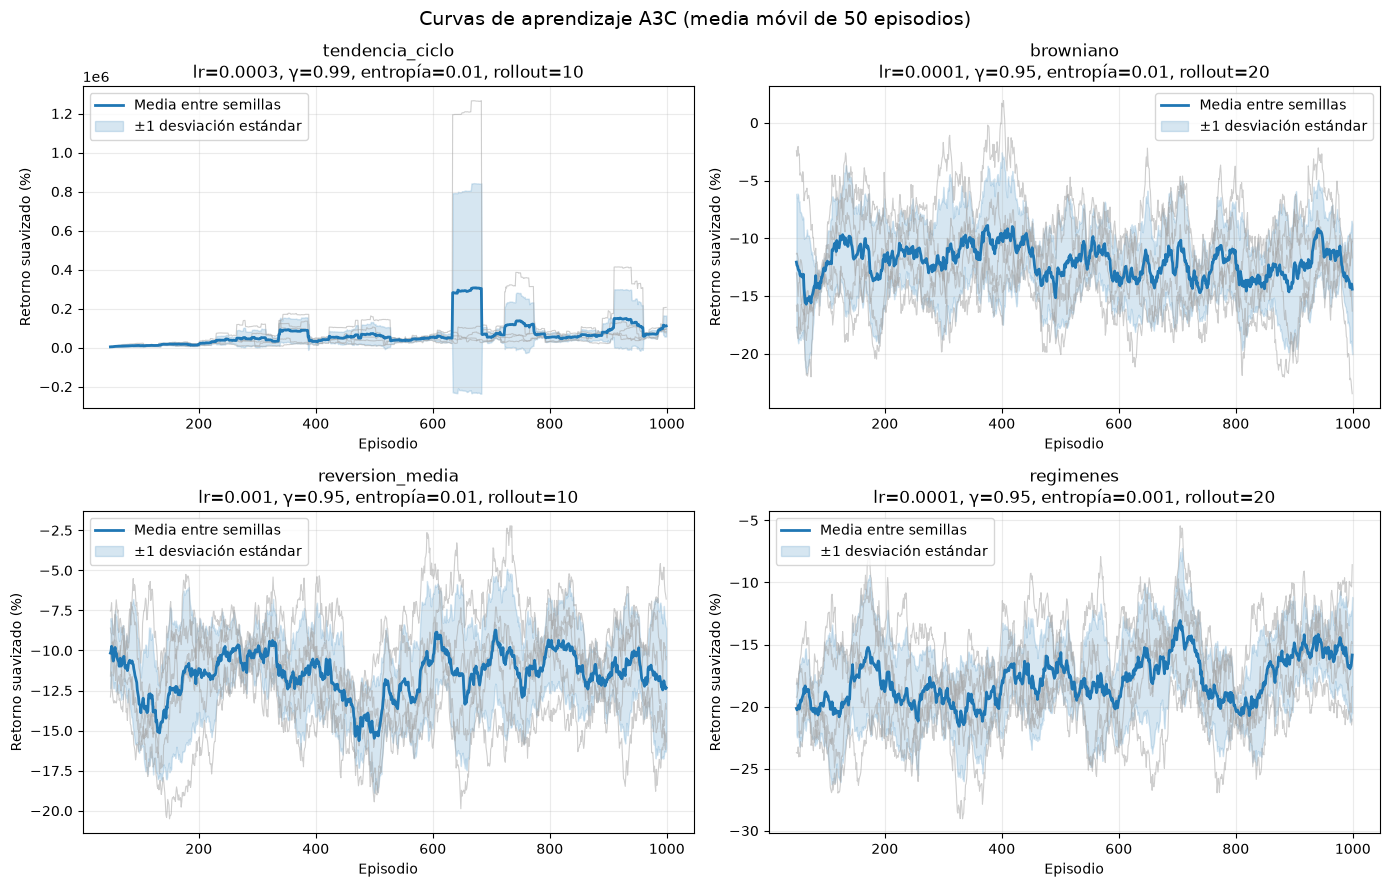

In [25]:
def plot_best_a3c_learning_curves(
    output_dir="artifacts/a3c_search",
    generator_names=None,
    smoothing_window=50,
    show_individual_seeds=True,
):
    """Representa el retorno de la mejor configuración de cada generador.

    La línea principal es la media entre semillas de sus retornos suavizados
    y la banda muestra una desviación estándar muestral.
    """
    if (
        isinstance(smoothing_window, (bool, np.bool_))
        or not isinstance(smoothing_window, (int, np.integer))
        or smoothing_window < 1
    ):
        raise ValueError("smoothing_window debe ser un entero positivo")

    if generator_names is None:
        generator_names = tuple(PRICE_GENERATORS)
    elif isinstance(generator_names, str):
        generator_names = (generator_names,)
    else:
        generator_names = tuple(generator_names)

    if not generator_names:
        raise ValueError("debe indicarse al menos un generador")
    unknown_generators = set(generator_names) - set(PRICE_GENERATORS)
    if unknown_generators:
        raise ValueError(
            f"generadores desconocidos: {sorted(unknown_generators)}"
        )

    output_dir = Path(output_dir)
    n_columns = min(2, len(generator_names))
    n_rows = (len(generator_names) + n_columns - 1) // n_columns
    fig, axes = plt.subplots(
        n_rows,
        n_columns,
        figsize=(7 * n_columns, 4.5 * n_rows),
        squeeze=False,
    )
    flat_axes = axes.ravel()
    smoothing_kernel = np.ones(smoothing_window) / smoothing_window

    for axis, generator_name in zip(flat_axes, generator_names):
        best_result = load_best_a3c_search_result(
            generator_name, output_dir
        )
        histories = [
            run["training_history"] for run in best_result["runs"]
        ]
        reference_episodes = np.asarray(histories[0]["episode"])
        if smoothing_window > reference_episodes.size:
            raise ValueError(
                "smoothing_window no puede superar el número de episodios"
            )

        smoothed_returns = []
        for history in histories:
            episodes = np.asarray(history["episode"])
            if not np.array_equal(episodes, reference_episodes):
                raise ValueError(
                    "los historiales no comparten los mismos episodios"
                )
            episode_returns = np.asarray(
                history["episode_return"], dtype=np.float64
            )
            smoothed_return = np.convolve(
                episode_returns, smoothing_kernel, mode="valid"
            )
            smoothed_returns.append(smoothed_return)
            if show_individual_seeds:
                axis.plot(
                    reference_episodes[smoothing_window - 1 :],
                    100.0 * smoothed_return,
                    color="0.65",
                    linewidth=0.8,
                    alpha=0.55,
                )

        smoothed_returns = np.stack(smoothed_returns)
        mean_return = smoothed_returns.mean(axis=0)
        return_std = smoothed_returns.std(
            axis=0, ddof=1 if len(histories) > 1 else 0
        )
        plotted_episodes = reference_episodes[smoothing_window - 1 :]
        axis.plot(
            plotted_episodes,
            100.0 * mean_return,
            color="tab:blue",
            linewidth=2.0,
            label="Media entre semillas",
        )
        axis.fill_between(
            plotted_episodes,
            100.0 * (mean_return - return_std),
            100.0 * (mean_return + return_std),
            color="tab:blue",
            alpha=0.18,
            label="±1 desviación estándar",
        )
        config = best_result["config"]
        axis.set_title(
            f"{generator_name}\n"
            f"lr={config.learning_rate:g}, γ={config.gamma:g}, "
            f"entropía={config.entropy_coefficient:g}, "
            f"rollout={config.rollout_steps}"
        )
        axis.set_xlabel("Episodio")
        axis.set_ylabel("Retorno suavizado (%)")
        axis.grid(alpha=0.25)
        axis.legend()

    for unused_axis in flat_axes[len(generator_names) :]:
        unused_axis.set_visible(False)

    fig.suptitle(
        f"Curvas de aprendizaje A3C (media móvil de "
        f"{smoothing_window} episodios)",
        fontsize=14,
    )
    fig.tight_layout()
    return fig, axes


fig, axes = plot_best_a3c_learning_curves()
plt.show()

### Estimación aproximada de la convergencia

Se reutiliza la lógica empleada en el enfoque tabular: el retorno se divide en bloques de episodios, se calcula el retorno medio de cada bloque y se comparan bloques consecutivos. La convergencia se sitúa en el primer bloque a partir del cual todos los cambios posteriores permanecen bajo el umbral, exigiendo además un número mínimo de cambios estables.

Aquí se usa por defecto un cambio **relativo** del 5 %, en vez del umbral absoluto de 0.005. Esta adaptación es necesaria porque los cuatro generadores producen retornos con escalas muy diferentes, especialmente `tendencia_ciclo`. El parámetro `scale_floor` evita que el cociente se vuelva inestable cuando el retorno del bloque anterior está cerca de cero.

Este criterio es retrospectivo y aproximado: describe la estabilización del retorno de entrenamiento, pero no demuestra que la política sea óptima ni sustituye la evaluación sobre validación. En A3C, el episodio estimado también debe interpretarse de forma aproximada porque los workers realizan actualizaciones simultáneas.

In [26]:
def estimate_a3c_convergence_episode(
    episode_returns,
    block_size=50,
    change_threshold=0.05,
    stable_blocks=3,
    relative=True,
    scale_floor=0.01,
):
    """Estima el primer episodio desde el que el retorno se estabiliza."""
    episode_returns = np.asarray(episode_returns, dtype=np.float64)
    if episode_returns.ndim != 1:
        raise ValueError("episode_returns debe ser un vector")
    if not np.all(np.isfinite(episode_returns)):
        raise ValueError("episode_returns debe contener valores finitos")
    if (
        isinstance(block_size, (bool, np.bool_))
        or not isinstance(block_size, (int, np.integer))
        or block_size <= 0
    ):
        raise ValueError("block_size debe ser un entero positivo")
    if change_threshold < 0:
        raise ValueError("change_threshold no puede ser negativo")
    if (
        isinstance(stable_blocks, (bool, np.bool_))
        or not isinstance(stable_blocks, (int, np.integer))
        or stable_blocks <= 0
    ):
        raise ValueError("stable_blocks debe ser un entero positivo")
    if not isinstance(relative, (bool, np.bool_)):
        raise ValueError("relative debe ser booleano")
    if scale_floor <= 0:
        raise ValueError("scale_floor debe ser positivo")

    n_complete_blocks = episode_returns.size // block_size
    if n_complete_blocks < stable_blocks + 1:
        return None

    usable_episodes = n_complete_blocks * block_size
    block_mean_returns = episode_returns[:usable_episodes].reshape(
        n_complete_blocks, block_size
    ).mean(axis=1)
    changes = np.abs(np.diff(block_mean_returns))
    if relative:
        scale = np.maximum(
            np.abs(block_mean_returns[:-1]), scale_floor
        )
        changes = changes / scale

    last_candidate = changes.size - stable_blocks
    for change_index in range(last_candidate + 1):
        if np.all(changes[change_index:] <= change_threshold):
            return int((change_index + 2) * block_size)

    return None


def summarize_a3c_runs_convergence(
    runs,
    n_episodes,
    block_size=50,
    change_threshold=0.05,
    stable_blocks=3,
    relative=True,
    scale_floor=0.01,
):
    """Agrega la convergencia estimada de varias semillas."""
    runs = tuple(runs)
    if not runs:
        raise ValueError("runs no puede estar vacío")
    if (
        isinstance(n_episodes, (bool, np.bool_))
        or not isinstance(n_episodes, (int, np.integer))
        or n_episodes <= 0
    ):
        raise ValueError("n_episodes debe ser un entero positivo")

    convergence_episodes = []
    convergence_seconds = []
    for run in runs:
        convergence_episode = estimate_a3c_convergence_episode(
            run["training_history"]["episode_return"],
            block_size=block_size,
            change_threshold=change_threshold,
            stable_blocks=stable_blocks,
            relative=relative,
            scale_floor=scale_floor,
        )
        convergence_episodes.append(convergence_episode)
        convergence_seconds.append(
            None
            if convergence_episode is None
            else run["training_seconds"]
            * convergence_episode
            / n_episodes
        )

    detected_episodes = [
        episode for episode in convergence_episodes if episode is not None
    ]
    detected_seconds = [
        seconds for seconds in convergence_seconds if seconds is not None
    ]
    return {
        "convergence_episodes": tuple(convergence_episodes),
        "estimated_convergence_seconds": tuple(convergence_seconds),
        "mean_convergence_episode": (
            float(np.mean(detected_episodes))
            if detected_episodes
            else None
        ),
        "mean_convergence_seconds": (
            float(np.mean(detected_seconds))
            if detected_seconds
            else None
        ),
        "convergence_rate": (
            len(detected_episodes) / len(convergence_episodes)
        ),
        "settings": {
            "block_size": block_size,
            "change_threshold": change_threshold,
            "stable_blocks": stable_blocks,
            "relative": relative,
            "scale_floor": scale_floor,
        },
    }


def summarize_best_a3c_convergence(
    output_dir="artifacts/a3c_search",
    generator_names=None,
    block_size=50,
    change_threshold=0.05,
    stable_blocks=3,
    relative=True,
    scale_floor=0.01,
):
    """Resume la convergencia de las semillas de cada mejor configuración."""
    if generator_names is None:
        generator_names = tuple(PRICE_GENERATORS)
    elif isinstance(generator_names, str):
        generator_names = (generator_names,)
    else:
        generator_names = tuple(generator_names)

    if not generator_names:
        raise ValueError("debe indicarse al menos un generador")
    unknown_generators = set(generator_names) - set(PRICE_GENERATORS)
    if unknown_generators:
        raise ValueError(
            f"generadores desconocidos: {sorted(unknown_generators)}"
        )

    output_dir = Path(output_dir)
    summaries = {}
    for generator_name in generator_names:
        best_result = load_best_a3c_search_result(
            generator_name, output_dir
        )
        convergence = summarize_a3c_runs_convergence(
            best_result["runs"],
            n_episodes=best_result["config"].n_episodes,
            block_size=block_size,
            change_threshold=change_threshold,
            stable_blocks=stable_blocks,
            relative=relative,
            scale_floor=scale_floor,
        )
        summaries[generator_name] = {
            "configuration_index": best_result["configuration_index"],
            **convergence,
        }

    return summaries


a3c_convergence = summarize_best_a3c_convergence()
for generator_name, summary in a3c_convergence.items():
    mean_episode = summary["mean_convergence_episode"]
    convergence_text = (
        "no detectada"
        if mean_episode is None
        else f"episodio medio {mean_episode:.0f}"
    )
    print(
        f"{generator_name}: {convergence_text}; "
        f"tasa={summary['convergence_rate']:.0%}"
    )

tendencia_ciclo: no detectada; tasa=0%
browniano: no detectada; tasa=0%
reversion_media: no detectada; tasa=0%
regimenes: no detectada; tasa=0%


### Comparación de 1.000 frente a 2.000 episodios

La ampliación se limita a `reversion_media` y `regimenes`. En **reversión a la media**, la mejor política obtiene un retorno positivo en validación y realiza operaciones, pero presenta variabilidad entre semillas; prolongar el entrenamiento permite comprobar si se estabiliza. En **cambios de régimen**, la política determinista termina permaneciendo en efectivo, aunque los últimos bloques de entrenamiento muestran una ligera mejora; el experimento comprueba si necesita más experiencia para aprovechar los cambios de régimen.

No se amplía **browniano** porque no contiene una señal predecible y la política validada de permanecer en efectivo es coherente con ese mercado y sus costes. Tampoco se amplía **tendencia_ciclo**: sus retornos tienen una escala extrema y una gran variabilidad debidas al generador, por lo que añadir episodios no resolvería el problema de interpretación; antes habría que revisar la dinámica de precios o la normalización de la recompensa.

Para que la comparación sea justa, se mantienen los hiperparámetros ganadores, las cinco semillas y el banco de validación. Los resultados ya disponibles de 1.000 episodios se reutilizan y cada entrenamiento de 2.000 episodios comienza desde cero. No se continúa desde los archivos `best_model.pt` porque estos conservan los pesos, pero no el estado del optimizador Adam. Cada semilla de 2.000 episodios se guarda al terminar, por lo que la ejecución puede reanudarse. El conjunto de test permanece sin utilizar.

In [27]:
A3C_TRAINING_LENGTH_GENERATORS = (
    "reversion_media",
    "regimenes",
)


class A3CTrainingLengthExperiment:
    """Compara la configuración ganadora con una duración mayor."""

    def __init__(
        self,
        generator_name,
        target_episodes=2_000,
        search_output_dir="artifacts/a3c_search",
        experiment_output_dir="artifacts/a3c_training_length",
    ):
        self.generator_name = generator_name
        self.search_output_dir = Path(search_output_dir)
        self.experiment_output_dir = Path(experiment_output_dir)
        self.base_result = load_best_a3c_search_result(
            generator_name, self.search_output_dir
        )
        base_config = self.base_result["config"]
        if target_episodes <= base_config.n_episodes:
            raise ValueError(
                "target_episodes debe superar la duración original"
            )
        self.extended_config = replace(
            base_config, n_episodes=target_episodes
        )
        self.checkpoint_path = (
            self.experiment_output_dir
            / f"{generator_name}_{target_episodes}_search.pt"
        )
        self.best_model_path = (
            self.experiment_output_dir
            / f"{generator_name}_{target_episodes}_best_model.pt"
        )

    def _build_result(self, runs):
        return {
            "configuration_index": self.base_result[
                "configuration_index"
            ],
            "config": self.extended_config,
            "runs": tuple(runs),
            "summary": aggregate_a3c_validation_runs(runs),
        }

    def _load_existing_runs(self):
        if not self.checkpoint_path.is_file():
            return []

        checkpoint = load_a3c_search_checkpoint(self.checkpoint_path)
        if checkpoint["generator_name"] != self.generator_name:
            raise ValueError(
                "el checkpoint pertenece a otro generador"
            )
        if len(checkpoint["search_results"]) != 1:
            raise ValueError(
                "el checkpoint de duración debe contener un resultado"
            )

        result = checkpoint["search_results"][0]
        if result["config"] != self.extended_config:
            raise ValueError(
                "la configuración guardada no coincide con el experimento"
            )
        runs = list(result["runs"])
        saved_seeds = {run["training_seed"] for run in runs}
        if not saved_seeds.issubset(set(TRAINING_SEEDS)):
            raise ValueError("el checkpoint contiene semillas inesperadas")
        return runs

    def _save_result(self, result):
        temporary_path = self.checkpoint_path.with_name(
            self.checkpoint_path.name + ".tmp"
        )
        save_a3c_search_checkpoint(
            checkpoint_path=temporary_path,
            generator_name=self.generator_name,
            training_seeds=TRAINING_SEEDS,
            search_results=(result,),
        )
        temporary_path.replace(self.checkpoint_path)

    def run(self, verbose=True):
        runs = self._load_existing_runs()
        completed_seeds = {run["training_seed"] for run in runs}
        if verbose and runs:
            print(
                f"{self.generator_name}: reanudando con "
                f"{len(runs)}/{len(TRAINING_SEEDS)} semillas"
            )

        trainer = A3CTrainer(self.generator_name, self.extended_config)
        for training_seed in TRAINING_SEEDS:
            if training_seed in completed_seeds:
                continue
            if verbose:
                print(
                    f"{self.generator_name} · "
                    f"{self.extended_config.n_episodes} episodios · "
                    f"semilla {training_seed}"
                )

            model, training_history = trainer.train(training_seed)
            validation = evaluate_a3c_on_validation(
                model, self.generator_name
            )
            runs.append(
                {
                    "training_seed": training_seed,
                    "training_seconds": training_history[
                        "training_seconds"
                    ],
                    "training_history": (
                        compact_a3c_training_history(training_history)
                    ),
                    "validation": validation,
                    "model_state_dict": {
                        name: tensor.detach().cpu().clone()
                        for name, tensor in model.state_dict().items()
                    },
                }
            )
            seed_order = {
                seed: index for index, seed in enumerate(TRAINING_SEEDS)
            }
            runs.sort(key=lambda run: seed_order[run["training_seed"]])
            result = self._build_result(runs)
            self._save_result(result)
            if verbose:
                print(
                    f"  retorno validación="
                    f"{validation['mean_return']:.4%}; "
                    f"tiempo={training_history['training_seconds']:.1f}s"
                )
            del model

        result = self._build_result(runs)
        if len(runs) == len(TRAINING_SEEDS):
            save_best_a3c_model((result,), self.best_model_path)
        return result


def run_a3c_training_length_experiments(
    generator_names=A3C_TRAINING_LENGTH_GENERATORS,
    target_episodes=2_000,
    verbose=True,
):
    """Ejecuta o reanuda las comparaciones de duración seleccionadas."""
    comparisons = {}
    for generator_name in generator_names:
        experiment = A3CTrainingLengthExperiment(
            generator_name=generator_name,
            target_episodes=target_episodes,
        )
        extended_result = experiment.run(verbose=verbose)
        comparisons[generator_name] = {
            experiment.base_result["config"].n_episodes: (
                experiment.base_result
            ),
            target_episodes: extended_result,
        }

    return comparisons

In [28]:
a3c_training_length_results = (
    run_a3c_training_length_experiments()
)

reversion_media: reanudando con 5/5 semillas
regimenes: reanudando con 5/5 semillas


reversion_media · 1000 episodios: retorno=11.8465%, p05=-5.1963%, std_semillas=11.8136%, operaciones=5.51, tiempo=98.1s, convergencia=no detectada, tasa=0%
reversion_media · 2000 episodios: retorno=14.1868%, p05=-4.8162%, std_semillas=15.2066%, operaciones=10.84, tiempo=197.4s, convergencia=no detectada, tasa=0%
regimenes · 1000 episodios: retorno=0.0000%, p05=0.0000%, std_semillas=0.0000%, operaciones=0.00, tiempo=83.0s, convergencia=no detectada, tasa=0%
regimenes · 2000 episodios: retorno=0.0000%, p05=0.0000%, std_semillas=0.0000%, operaciones=0.00, tiempo=165.1s, convergencia=no detectada, tasa=0%


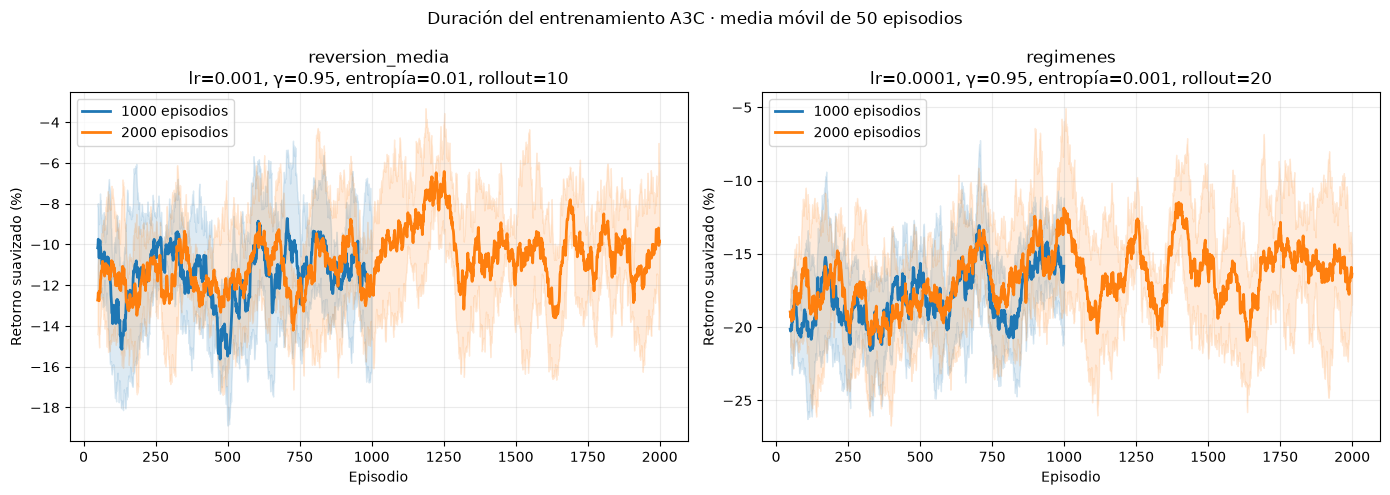

In [29]:
def summarize_a3c_training_length_comparison(comparisons):
    """Construye filas comparables de validación y convergencia."""
    rows = []
    for generator_name, results_by_duration in comparisons.items():
        for n_episodes, result in sorted(results_by_duration.items()):
            validation = result["summary"]
            convergence = summarize_a3c_runs_convergence(
                result["runs"], n_episodes=n_episodes
            )
            rows.append(
                {
                    "generator_name": generator_name,
                    "n_episodes": n_episodes,
                    "mean_return": validation["mean_return"],
                    "std_between_seeds": validation[
                        "std_between_seeds"
                    ],
                    "return_percentile_05": validation[
                        "return_percentile_05"
                    ],
                    "mean_trade_count": validation[
                        "mean_trade_count"
                    ],
                    "mean_training_seconds": validation[
                        "mean_training_seconds"
                    ],
                    **convergence,
                }
            )
    return tuple(rows)


def print_a3c_training_length_comparison(rows):
    """Muestra las métricas principales de ambas duraciones."""
    for row in rows:
        convergence_episode = row["mean_convergence_episode"]
        convergence_text = (
            "no detectada"
            if convergence_episode is None
            else f"{convergence_episode:.0f}"
        )
        print(
            f"{row['generator_name']} · {row['n_episodes']} episodios: "
            f"retorno={row['mean_return']:.4%}, "
            f"p05={row['return_percentile_05']:.4%}, "
            f"std_semillas={row['std_between_seeds']:.4%}, "
            f"operaciones={row['mean_trade_count']:.2f}, "
            f"tiempo={row['mean_training_seconds']:.1f}s, "
            f"convergencia={convergence_text}, "
            f"tasa={row['convergence_rate']:.0%}"
        )


def plot_a3c_training_length_comparison(
    comparisons, smoothing_window=50
):
    """Compara las curvas de 1.000 y 2.000 episodios."""
    if smoothing_window <= 0:
        raise ValueError("smoothing_window debe ser positivo")
    figure, axes = plt.subplots(
        1, len(comparisons), figsize=(7 * len(comparisons), 5),
        squeeze=False,
    )
    colors = ("tab:blue", "tab:orange", "tab:green")
    for axis, (generator_name, results_by_duration) in zip(
        axes.ravel(), comparisons.items()
    ):
        for color, (n_episodes, result) in zip(
            colors, sorted(results_by_duration.items())
        ):
            histories = [
                run["training_history"] for run in result["runs"]
            ]
            kernel = np.ones(smoothing_window) / smoothing_window
            curves = np.stack(
                [
                    np.convolve(
                        history["episode_return"], kernel, mode="valid"
                    )
                    for history in histories
                ]
            )
            episodes = np.asarray(histories[0]["episode"])[
                smoothing_window - 1 :
            ]
            mean_curve = curves.mean(axis=0)
            std_curve = curves.std(
                axis=0, ddof=1 if len(curves) > 1 else 0
            )
            axis.plot(
                episodes, 100 * mean_curve, color=color,
                linewidth=2, label=f"{n_episodes} episodios",
            )
            axis.fill_between(
                episodes,
                100 * (mean_curve - std_curve),
                100 * (mean_curve + std_curve),
                color=color, alpha=0.15,
            )

        config = next(iter(results_by_duration.values()))["config"]
        axis.set_title(
            f"{generator_name}\n"
            f"lr={config.learning_rate:g}, γ={config.gamma:g}, "
            f"entropía={config.entropy_coefficient:g}, "
            f"rollout={config.rollout_steps}"
        )
        axis.set_xlabel("Episodio")
        axis.set_ylabel("Retorno suavizado (%)")
        axis.grid(alpha=0.25)
        axis.legend()

    figure.suptitle(
        f"Duración del entrenamiento A3C · media móvil de "
        f"{smoothing_window} episodios"
    )
    figure.tight_layout()
    return figure, axes


a3c_training_length_summary = (
    summarize_a3c_training_length_comparison(
        a3c_training_length_results
    )
)
print_a3c_training_length_comparison(a3c_training_length_summary)
fig, axes = plot_a3c_training_length_comparison(
    a3c_training_length_results
)
plt.show()

#### Conclusión sobre la duración del entrenamiento

En `reversion_media`, ampliar de 1.000 a 2.000 episodios eleva el retorno medio de validación de **11,8465 %** a **14,1868 %** y mejora ligeramente el percentil 5, de **−5,1963 %** a **−4,8162 %**. Sin embargo, la desviación entre semillas aumenta de **11,8136 %** a **15,2066 %**, el número medio de operaciones pasa de **5,51** a **10,84** y el tiempo medio prácticamente se duplica, de **98,1 s** a **197,4 s**. Solo tres de las cinco semillas mejoran; las otras dos empeoran, y ninguna duración cumple el criterio aproximado de convergencia. La ganancia media de 2,34 puntos porcentuales no es suficientemente consistente para afirmar que 2.000 episodios sean mejores. Se mantienen 1.000 episodios como opción más eficiente y estable, dejando el modelo de 2.000 guardado para análisis posteriores.

En `regimenes`, tanto 1.000 como 2.000 episodios producen un retorno de validación del **0 %**, cero operaciones y una tasa de convergencia del **0 %** en las cinco semillas. Duplicar la duración solo aumenta el tiempo medio de **83,0 s** a **165,1 s**. Por tanto, se mantienen 1.000 episodios y se concluye que, con la representación del estado y los hiperparámetros actuales, el problema no se resuelve simplemente prolongando el entrenamiento.

Esta decisión se ha tomado exclusivamente con entrenamiento y validación; el conjunto de test continúa sin utilizarse.

### Evaluación final sobre test

Las decisiones quedan congeladas antes de acceder a test: se mantienen 1.000 episodios y la configuración seleccionada en validación para los cuatro generadores. Para evitar el sesgo de escoger la mejor semilla, se evalúan los cinco modelos de cada configuración sobre las mismas 200 series de test y se agregan sus 1.000 retornos. La acción de A3C se elige de forma determinista mediante `argmax`.

Los baselines de efectivo, *buy & hold* y agente aleatorio se ejecutan sobre exactamente las mismas series. *Buy & hold* compra una vez en el primer instante disponible y mantiene la posición, por lo que paga la misma comisión de compra que el entorno. El agente aleatorio utiliza `TEST_PROTOCOL.action_rng`, con una secuencia independiente y reproducible por generador y serie.

Antes de evaluar se comprueban las huellas SHA-256 fijadas por el protocolo. Los resultados se guardan después de cada generador y el artefacto completo se reutiliza en ejecuciones posteriores, evitando volver a consultar test. A partir de este punto, test solo se usa para informar el rendimiento final y no para cambiar modelos, hiperparámetros o duración.

In [30]:
EXPECTED_TEST_FINGERPRINTS = {
    "tendencia_ciclo": (
        "f7ba229a24755ad123d0b01e608ed72e16f347bb16be7c87fd309e1afb38763d"
    ),
    "browniano": (
        "d05b4102b634985e678b6a0511fcd0497d524f3b4b72d396043ebe25e362688d"
    ),
    "reversion_media": (
        "16ac74754351e609c738490d97f7c69383a10a31c4920d4b25423df215d86339"
    ),
    "regimenes": (
        "061f1f1ef1f21f034eea600b65d5d87702d4430699cf38250fb552fb58b013ce"
    ),
}
A3C_FINAL_EPISODES = {name: 1_000 for name in PRICE_GENERATORS}


def evaluate_rule_based_policy(price_dataset, policy_factory):
    """Evalúa una política creada independientemente para cada serie."""
    dataset = np.asarray(price_dataset, dtype=np.float64)
    if dataset.ndim != 2 or dataset.shape[0] == 0:
        raise ValueError("price_dataset debe ser una matriz no vacía")
    if dataset.shape[1] < 7:
        raise ValueError("cada serie debe contener al menos 7 precios")
    if not np.all(np.isfinite(dataset)) or np.any(dataset <= 0.0):
        raise ValueError("todos los precios deben ser finitos y positivos")
    if not callable(policy_factory):
        raise TypeError("policy_factory debe ser invocable")

    episode_rewards = []
    final_balances = []
    episode_returns = []
    action_counts = []
    trade_counts = []
    evaluation_start = perf_counter()

    for series_index, prices in enumerate(dataset):
        env = SimpleTradingEnv(prices)
        observation, _ = env.reset()
        select_action = policy_factory(series_index)
        if not callable(select_action):
            raise TypeError("policy_factory debe devolver una política")
        terminated = False
        truncated = False
        total_reward = 0.0
        episode_action_counts = np.zeros(
            env.action_space.n, dtype=np.int64
        )
        episode_trade_count = 0
        info = {"balance": env.balance}

        while not (terminated or truncated):
            action = select_action(observation, env)
            if (
                isinstance(action, (bool, np.bool_))
                or not isinstance(action, (int, np.integer))
                or not env.action_space.contains(int(action))
            ):
                raise ValueError(f"la política produjo una acción inválida: {action}")
            action = int(action)
            previous_position = env.position
            episode_action_counts[action] += 1
            observation, reward, terminated, truncated, info = env.step(
                action
            )
            episode_trade_count += int(env.position != previous_position)
            total_reward += float(reward)

        final_balance = float(info["balance"])
        episode_rewards.append(total_reward)
        final_balances.append(final_balance)
        episode_returns.append(final_balance / env.initial_balance - 1.0)
        action_counts.append(episode_action_counts)
        trade_counts.append(episode_trade_count)

    evaluation_seconds = perf_counter() - evaluation_start
    episode_rewards = np.asarray(episode_rewards, dtype=np.float64)
    final_balances = np.asarray(final_balances, dtype=np.float64)
    episode_returns = np.asarray(episode_returns, dtype=np.float64)
    action_counts = np.stack(action_counts)
    trade_counts = np.asarray(trade_counts, dtype=np.int64)
    total_action_counts = action_counts.sum(axis=0)
    return {
        "n_series": int(dataset.shape[0]),
        "episode_rewards": episode_rewards,
        "final_balances": final_balances,
        "returns": episode_returns,
        "action_counts": action_counts,
        "trade_counts": trade_counts,
        "total_action_counts": total_action_counts,
        "action_frequencies": (
            total_action_counts / total_action_counts.sum()
        ),
        "mean_episode_reward": float(episode_rewards.mean()),
        "mean_final_balance": float(final_balances.mean()),
        "mean_return": float(episode_returns.mean()),
        "std_return": float(episode_returns.std()),
        "median_return": float(np.median(episode_returns)),
        "return_percentile_05": float(
            np.percentile(episode_returns, 5)
        ),
        "return_percentile_95": float(
            np.percentile(episode_returns, 95)
        ),
        "mean_trade_count": float(trade_counts.mean()),
        "evaluation_seconds": float(evaluation_seconds),
    }


def evaluate_test_baselines(generator_name):
    """Evalúa los tres baselines bajo las semillas comunes de test."""
    if generator_name not in PRICE_GENERATORS:
        raise ValueError(f"generador desconocido: {generator_name}")
    generator_id, _ = PRICE_GENERATORS[generator_name]
    dataset = TEST_DATASETS[generator_name]

    def cash_factory(series_index):
        return lambda observation, env: 1

    def buy_and_hold_factory(series_index):
        first_action = True

        def select_action(observation, env):
            nonlocal first_action
            if first_action:
                first_action = False
                return 2
            return 1

        return select_action

    def random_factory(series_index):
        rng = TEST_PROTOCOL.action_rng(generator_id, series_index)
        return lambda observation, env: int(
            rng.integers(env.action_space.n)
        )

    return {
        "cash": evaluate_rule_based_policy(dataset, cash_factory),
        "buy_and_hold": evaluate_rule_based_policy(
            dataset, buy_and_hold_factory
        ),
        "random": evaluate_rule_based_policy(dataset, random_factory),
    }


def aggregate_a3c_test_evaluations(model_evaluations):
    """Agrega test sobre series y sobre semillas de entrenamiento."""
    model_evaluations = tuple(model_evaluations)
    if tuple(
        evaluation["training_seed"] for evaluation in model_evaluations
    ) != TRAINING_SEEDS:
        raise ValueError("test debe contener las cinco semillas en orden")

    returns = np.stack(
        [evaluation["returns"] for evaluation in model_evaluations]
    )
    trade_counts = np.stack(
        [evaluation["trade_counts"] for evaluation in model_evaluations]
    )
    total_action_counts = np.stack(
        [
            evaluation["total_action_counts"]
            for evaluation in model_evaluations
        ]
    ).sum(axis=0)
    seed_mean_returns = returns.mean(axis=1)
    pooled_returns = returns.reshape(-1)
    evaluation_seconds = np.asarray(
        [
            evaluation["evaluation_seconds"]
            for evaluation in model_evaluations
        ],
        dtype=np.float64,
    )
    return {
        "n_training_seeds": len(model_evaluations),
        "n_series_per_seed": int(returns.shape[1]),
        "returns_by_seed": returns,
        "seed_mean_returns": seed_mean_returns,
        "pooled_returns": pooled_returns,
        "mean_return": float(pooled_returns.mean()),
        "std_return": float(pooled_returns.std()),
        "std_between_seeds": float(seed_mean_returns.std(ddof=1)),
        "return_percentile_05": float(
            np.percentile(pooled_returns, 5)
        ),
        "return_percentile_95": float(
            np.percentile(pooled_returns, 95)
        ),
        "mean_trade_count": float(trade_counts.mean()),
        "total_action_counts": total_action_counts,
        "action_frequencies": (
            total_action_counts / total_action_counts.sum()
        ),
        "total_evaluation_seconds": float(evaluation_seconds.sum()),
        "mean_evaluation_seconds_per_seed": float(
            evaluation_seconds.mean()
        ),
    }


class A3CFinalTestEvaluator:
    """Ejecuta test una vez y reutiliza el artefacto definitivo."""

    FORMAT_VERSION = 1

    def __init__(
        self,
        output_path="artifacts/a3c_final_test/final_test_results.pt",
        search_output_dir="artifacts/a3c_search",
    ):
        self.output_path = Path(output_path)
        self.search_output_dir = Path(search_output_dir)
        self._verify_protocol()

    @staticmethod
    def _verify_protocol():
        if (
            TEST_PROTOCOL.n_series != 200
            or TEST_PROTOCOL.n_steps != 500
            or TEST_PROTOCOL.price_seed != 10_000
            or TEST_PROTOCOL.action_seed != 20_000
        ):
            raise ValueError("la configuración de TEST_PROTOCOL ha cambiado")
        observed_fingerprints = {
            name: dataset_fingerprint(dataset)
            for name, dataset in TEST_DATASETS.items()
        }
        if observed_fingerprints != EXPECTED_TEST_FINGERPRINTS:
            raise ValueError("las huellas del banco de test no coinciden")

    def _new_payload(self):
        return {
            "format_version": self.FORMAT_VERSION,
            "status": "partial",
            "protocol": asdict(TEST_PROTOCOL),
            "dataset_fingerprints": dict(EXPECTED_TEST_FINGERPRINTS),
            "training_seeds": TRAINING_SEEDS,
            "selected_episodes": dict(A3C_FINAL_EPISODES),
            "generator_results": {},
            "torch_version": torch.__version__,
        }

    def _load_payload(self):
        payload = torch.load(
            self.output_path, map_location="cpu", weights_only=False
        )
        if payload.get("format_version") != self.FORMAT_VERSION:
            raise ValueError("versión del resultado final no compatible")
        if payload.get("dataset_fingerprints") != EXPECTED_TEST_FINGERPRINTS:
            raise ValueError("el resultado usa otro banco de test")
        if payload.get("selected_episodes") != A3C_FINAL_EPISODES:
            raise ValueError("el resultado usa otra duración de entrenamiento")
        return payload

    def _save_payload(self, payload):
        self.output_path.parent.mkdir(parents=True, exist_ok=True)
        temporary_path = self.output_path.with_name(
            self.output_path.name + ".tmp"
        )
        torch.save(payload, temporary_path)
        temporary_path.replace(self.output_path)

    def _evaluate_generator(self, generator_name):
        best_result = load_best_a3c_search_result(
            generator_name, self.search_output_dir
        )
        config = best_result["config"]
        if config.n_episodes != A3C_FINAL_EPISODES[generator_name]:
            raise ValueError(
                f"duración inesperada para {generator_name}"
            )
        runs_by_seed = {
            run["training_seed"]: run for run in best_result["runs"]
        }
        if set(runs_by_seed) != set(TRAINING_SEEDS):
            raise ValueError("faltan semillas de entrenamiento")

        dataset = TEST_DATASETS[generator_name]
        model_evaluations = []
        for training_seed in TRAINING_SEEDS:
            run = runs_by_seed[training_seed]
            model = ActorCriticNetwork(
                observation_dim=2, action_dim=3,
                hidden_dim=config.hidden_dim,
            )
            model.load_state_dict(run["model_state_dict"])
            evaluation = evaluate_a3c_deterministically(model, dataset)
            model_evaluations.append(
                {"training_seed": training_seed, **evaluation}
            )
            del model

        aggregate = aggregate_a3c_test_evaluations(model_evaluations)
        aggregate["mean_training_seconds"] = float(
            np.mean(
                [run["training_seconds"] for run in best_result["runs"]]
            )
        )
        return {
            "configuration_index": best_result["configuration_index"],
            "config": asdict(config),
            "a3c_model_evaluations": tuple(model_evaluations),
            "a3c_aggregate": aggregate,
            "baselines": evaluate_test_baselines(generator_name),
        }

    def run(self, verbose=True):
        if self.output_path.is_file():
            payload = self._load_payload()
            if payload.get("status") == "complete":
                if verbose:
                    print("Cargando la evaluación final ya completada")
                return payload
        else:
            payload = self._new_payload()

        completed = payload["generator_results"]
        for generator_name in PRICE_GENERATORS:
            if generator_name in completed:
                continue
            if verbose:
                print(f"Test final: {generator_name}")
            completed[generator_name] = self._evaluate_generator(
                generator_name
            )
            self._save_payload(payload)

        payload["status"] = "complete"
        self._save_payload(payload)
        return payload


def build_a3c_final_test_rows(payload):
    """Convierte el artefacto final en filas comparables."""
    if payload.get("status") != "complete":
        raise ValueError("la evaluación final todavía no está completa")
    rows = []
    baseline_labels = {
        "cash": "Efectivo",
        "buy_and_hold": "Buy & Hold",
        "random": "Aleatorio",
    }
    for generator_name, result in payload["generator_results"].items():
        config = result["config"]
        training_result = load_best_a3c_search_result(generator_name)
        convergence = summarize_a3c_runs_convergence(
            training_result["runs"],
            n_episodes=config["n_episodes"],
        )
        a3c = result["a3c_aggregate"]
        rows.append(
            {
                "generator_name": generator_name,
                "model": "A3C",
                "n_episodes": config["n_episodes"],
                "n_steps": config["n_steps"],
                "learning_rate": config["learning_rate"],
                "gamma": config["gamma"],
                "entropy_coefficient": config[
                    "entropy_coefficient"
                ],
                "rollout_steps": config["rollout_steps"],
                "mean_return": a3c["mean_return"],
                "std_return": a3c["std_return"],
                "std_between_seeds": a3c["std_between_seeds"],
                "return_percentile_05": a3c["return_percentile_05"],
                "mean_trade_count": a3c["mean_trade_count"],
                "evaluation_seconds": a3c[
                    "mean_evaluation_seconds_per_seed"
                ],
                "training_seconds": a3c["mean_training_seconds"],
                "convergence_episode": convergence[
                    "mean_convergence_episode"
                ],
                "convergence_seconds": convergence[
                    "mean_convergence_seconds"
                ],
                "convergence_rate": convergence[
                    "convergence_rate"
                ],
            }
        )
        for baseline_key, baseline_label in baseline_labels.items():
            baseline = result["baselines"][baseline_key]
            rows.append(
                {
                    "generator_name": generator_name,
                    "model": baseline_label,
                    "n_episodes": None,
                    "n_steps": None,
                    "learning_rate": None,
                    "gamma": None,
                    "entropy_coefficient": None,
                    "rollout_steps": None,
                    "mean_return": baseline["mean_return"],
                    "std_return": baseline["std_return"],
                    "std_between_seeds": None,
                    "return_percentile_05": baseline[
                        "return_percentile_05"
                    ],
                    "mean_trade_count": baseline[
                        "mean_trade_count"
                    ],
                    "evaluation_seconds": baseline[
                        "evaluation_seconds"
                    ],
                    "training_seconds": None,
                    "convergence_episode": None,
                    "convergence_seconds": None,
                    "convergence_rate": None,
                }
            )
    return tuple(rows)


def print_a3c_final_test_rows(rows):
    """Muestra las métricas definitivas con nombres no ambiguos."""
    for row in rows:
        seed_std = row["std_between_seeds"]
        seed_std_text = (
            "N/A" if seed_std is None else f"{seed_std:.4%}"
        )
        training_time = row["training_seconds"]
        training_time_text = (
            "N/A" if training_time is None else f"{training_time:.1f}s"
        )
        print(
            f"{row['generator_name']} · {row['model']}: "
            f"retorno={row['mean_return']:.4%}, "
            f"std_series={row['std_return']:.4%}, "
            f"std_semillas={seed_std_text}, "
            f"p05={row['return_percentile_05']:.4%}, "
            f"operaciones={row['mean_trade_count']:.2f}, "
            f"eval={row['evaluation_seconds']:.2f}s, "
            f"train={training_time_text}"
        )

In [31]:
a3c_final_test_results = A3CFinalTestEvaluator().run()
a3c_final_test_rows = build_a3c_final_test_rows(
    a3c_final_test_results
)
print_a3c_final_test_rows(a3c_final_test_rows)

Cargando la evaluación final ya completada
tendencia_ciclo · A3C: retorno=248957.3476%, std_series=1568372.0365%, std_semillas=47695.7411%, p05=1893.3681%, operaciones=81.59, eval=1.88s, train=96.3s
tendencia_ciclo · Efectivo: retorno=0.0000%, std_series=0.0000%, std_semillas=N/A, p05=0.0000%, operaciones=0.00, eval=0.44s, train=N/A
tendencia_ciclo · Buy & Hold: retorno=42092.9049%, std_series=318054.9209%, std_semillas=N/A, p05=-16.6753%, operaciones=1.00, eval=0.45s, train=N/A
tendencia_ciclo · Aleatorio: retorno=1479.7505%, std_series=3585.0360%, std_semillas=N/A, p05=-74.8196%, operaciones=165.69, eval=0.52s, train=N/A
browniano · A3C: retorno=0.0000%, std_series=0.0000%, std_semillas=0.0000%, p05=0.0000%, operaciones=0.00, eval=1.89s, train=82.2s
browniano · Efectivo: retorno=0.0000%, std_series=0.0000%, std_semillas=N/A, p05=0.0000%, operaciones=0.00, eval=0.45s, train=N/A
browniano · Buy & Hold: retorno=9.0815%, std_series=50.2814%, std_semillas=N/A, p05=-51.1621%, operaciones=1

#### Conclusiones de test

- En `tendencia_ciclo`, A3C alcanza un retorno medio de **248.957,35 %** y un percentil 5 de **1.893,37 %**, por encima del *buy & hold* en ambas métricas. Sin embargo, la desviación entre series es **1.568.372,04 %** y la desviación entre semillas **47.695,74 %**. Estas magnitudes reflejan principalmente la dinámica explosiva del generador y obligan a interpretar el resultado con cautela; no es evidencia de que esos retornos sean trasladables a un mercado real.
- En `browniano`, A3C reproduce la política de efectivo: retorno y operaciones iguales a cero. *Buy & hold* obtiene un retorno medio superior (**9,08 %**), pero con un percentil 5 de **−51,16 %**; el agente aleatorio pierde **−10,62 %** de media. A3C ha aprendido una solución conservadora, no la de mayor retorno medio en test.
- En `reversion_media`, A3C obtiene **11,12 %** de retorno medio, percentil 5 de **−6,55 %** y **5,45** operaciones. Supera a efectivo (**0 %**), *buy & hold* (**−0,30 %**) y aleatorio (**−13,04 %**). Es el resultado más informativo del experimento, aunque la desviación entre semillas de **12,24 %** confirma una sensibilidad relevante al entrenamiento.
- En `regimenes`, A3C vuelve a permanecer en efectivo y obtiene **0 %**. Esto evita las pérdidas medias de *buy & hold* (**−9,21 %**) y del agente aleatorio (**−18,81 %**), pero no demuestra que haya aprendido a explotar activamente los cambios de régimen.

Los resultados proceden del protocolo fijado de 200 series por generador y de las cinco semillas de entrenamiento. No se modifica ninguna decisión tras observar test.

### Tabla comparativa final

La tabla reúne los resultados definitivos de A3C y los tres baselines. `Desv. series` mide la dispersión de los retornos entre episodios de test, mientras que `Desv. semillas` mide la variación entre los retornos medios de las cinco semillas de entrenamiento. Los tiempos de evaluación corresponden a 200 series; para A3C se muestra el promedio por modelo.

In [32]:
def display_test_comparison_table(rows):
    """Muestra los resultados finales como una tabla Markdown."""
    from IPython.display import Markdown, display

    rows = tuple(rows)
    if not rows:
        raise ValueError("rows no puede estar vacío")

    headers = (
        "Generador",
        "Modelo",
        "Episodios",
        "Pasos",
        "LR",
        "γ",
        "Entropía",
        "Rollout",
        "Retorno test",
        "Desv. series",
        "Desv. semillas",
        "P05",
        "Operaciones",
        "Train/semilla (s)",
        "Eval/200 series (s)",
        "Conv. episodio",
        "Conv. segundos",
        "Tasa conv.",
    )
    table = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |",
    ]

    for row in rows:
        is_a3c = row["model"] == "A3C"
        if is_a3c:
            parameters = (
                str(row["n_episodes"]),
                str(row["n_steps"]),
                f"{row['learning_rate']:g}",
                f"{row['gamma']:g}",
                f"{row['entropy_coefficient']:g}",
                str(row["rollout_steps"]),
            )
            seed_std = f"{row['std_between_seeds']:.4%}"
            training_seconds = f"{row['training_seconds']:.1f}"
            convergence_episode = (
                "No detectada"
                if row["convergence_episode"] is None
                else f"{row['convergence_episode']:.0f}"
            )
            convergence_seconds = (
                "No detectada"
                if row["convergence_seconds"] is None
                else f"{row['convergence_seconds']:.1f}"
            )
            convergence_rate = f"{row['convergence_rate']:.0%}"
        else:
            parameters = ("—",) * 6
            seed_std = "N/A"
            training_seconds = "N/A"
            convergence_episode = "N/A"
            convergence_seconds = "N/A"
            convergence_rate = "N/A"

        values = (
            row["generator_name"],
            row["model"],
            *parameters,
            f"{row['mean_return']:.4%}",
            f"{row['std_return']:.4%}",
            seed_std,
            f"{row['return_percentile_05']:.4%}",
            f"{row['mean_trade_count']:.2f}",
            training_seconds,
            f"{row['evaluation_seconds']:.2f}",
            convergence_episode,
            convergence_seconds,
            convergence_rate,
        )
        table.append("| " + " | ".join(values) + " |")

    markdown_table = "\n".join(table)
    display(Markdown(markdown_table))
    return markdown_table


display_test_comparison_table(a3c_final_test_rows)

| Generador | Modelo | Episodios | Pasos | LR | γ | Entropía | Rollout | Retorno test | Desv. series | Desv. semillas | P05 | Operaciones | Train/semilla (s) | Eval/200 series (s) | Conv. episodio | Conv. segundos | Tasa conv. |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| tendencia_ciclo | A3C | 1000 | 500 | 0.0003 | 0.99 | 0.01 | 10 | 248957.3476% | 1568372.0365% | 47695.7411% | 1893.3681% | 81.59 | 96.3 | 1.88 | No detectada | No detectada | 0% |
| tendencia_ciclo | Efectivo | — | — | — | — | — | — | 0.0000% | 0.0000% | N/A | 0.0000% | 0.00 | N/A | 0.44 | N/A | N/A | N/A |
| tendencia_ciclo | Buy & Hold | — | — | — | — | — | — | 42092.9049% | 318054.9209% | N/A | -16.6753% | 1.00 | N/A | 0.45 | N/A | N/A | N/A |
| tendencia_ciclo | Aleatorio | — | — | — | — | — | — | 1479.7505% | 3585.0360% | N/A | -74.8196% | 165.69 | N/A | 0.52 | N/A | N/A | N/A |
| browniano | A3C | 1000 | 500 | 0.0001 | 0.95 | 0.01 | 20 | 0.0000% | 0.0000% | 0.0000% | 0.0000% | 0.00 | 82.2 | 1.89 | No detectada | No detectada | 0% |
| browniano | Efectivo | — | — | — | — | — | — | 0.0000% | 0.0000% | N/A | 0.0000% | 0.00 | N/A | 0.45 | N/A | N/A | N/A |
| browniano | Buy & Hold | — | — | — | — | — | — | 9.0815% | 50.2814% | N/A | -51.1621% | 1.00 | N/A | 0.45 | N/A | N/A | N/A |
| browniano | Aleatorio | — | — | — | — | — | — | -10.6240% | 32.6169% | N/A | -51.3174% | 164.91 | N/A | 0.53 | N/A | N/A | N/A |
| reversion_media | A3C | 1000 | 500 | 0.001 | 0.95 | 0.01 | 10 | 11.1212% | 17.3367% | 12.2351% | -6.5507% | 5.45 | 98.1 | 1.89 | No detectada | No detectada | 0% |
| reversion_media | Efectivo | — | — | — | — | — | — | 0.0000% | 0.0000% | N/A | 0.0000% | 0.00 | N/A | 0.44 | N/A | N/A | N/A |
| reversion_media | Buy & Hold | — | — | — | — | — | — | -0.3011% | 7.5959% | N/A | -11.6834% | 1.00 | N/A | 0.45 | N/A | N/A | N/A |
| reversion_media | Aleatorio | — | — | — | — | — | — | -13.0358% | 20.5917% | N/A | -41.5767% | 165.78 | N/A | 0.53 | N/A | N/A | N/A |
| regimenes | A3C | 1000 | 500 | 0.0001 | 0.95 | 0.001 | 20 | 0.0000% | 0.0000% | 0.0000% | 0.0000% | 0.00 | 83.0 | 1.91 | No detectada | No detectada | 0% |
| regimenes | Efectivo | — | — | — | — | — | — | 0.0000% | 0.0000% | N/A | 0.0000% | 0.00 | N/A | 0.45 | N/A | N/A | N/A |
| regimenes | Buy & Hold | — | — | — | — | — | — | -9.2115% | 38.7227% | N/A | -61.7607% | 1.00 | N/A | 0.47 | N/A | N/A | N/A |
| regimenes | Aleatorio | — | — | — | — | — | — | -18.8145% | 25.3327% | N/A | -56.7621% | 165.22 | N/A | 0.53 | N/A | N/A | N/A |

'| Generador | Modelo | Episodios | Pasos | LR | γ | Entropía | Rollout | Retorno test | Desv. series | Desv. semillas | P05 | Operaciones | Train/semilla (s) | Eval/200 series (s) | Conv. episodio | Conv. segundos | Tasa conv. |\n| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |\n| tendencia_ciclo | A3C | 1000 | 500 | 0.0003 | 0.99 | 0.01 | 10 | 248957.3476% | 1568372.0365% | 47695.7411% | 1893.3681% | 81.59 | 96.3 | 1.88 | No detectada | No detectada | 0% |\n| tendencia_ciclo | Efectivo | — | — | — | — | — | — | 0.0000% | 0.0000% | N/A | 0.0000% | 0.00 | N/A | 0.44 | N/A | N/A | N/A |\n| tendencia_ciclo | Buy & Hold | — | — | — | — | — | — | 42092.9049% | 318054.9209% | N/A | -16.6753% | 1.00 | N/A | 0.45 | N/A | N/A | N/A |\n| tendencia_ciclo | Aleatorio | — | — | — | — | — | — | 1479.7505% | 3585.0360% | N/A | -74.8196% | 165.69 | N/A | 0.52 | N/A | N/A | N/A |\n| browniano | A3C | 1000 | 500 | 0.0001 | 0.95 | 0.01 | 20 | 